# 🔥 Data Storytelling — สถิติอัคคีภัยประเทศไทย ปี พ.ศ. 2562
---



##Introduction

เหตุเพลิงไหม้เป็นหนึ่งในภัยพิบัติที่สามารถสร้างความเสียหาย
ต่อชีวิตและทรัพย์สินของประชาชนได้อย่างรุนแรงในแต่ละปี
การทำความเข้าใจรูปแบบและสาเหตุของการเกิดอัคคีภัย
จึงมีความสำคัญต่อการวางแผนป้องกันและลดความเสี่ยง
ของเหตุการณ์ดังกล่าว

--------------------------------------------------

ในการวิเคราะห์ครั้งนี้ เราใช้ชุดข้อมูล
"สถิติการเกิดอัคคีภัยในประเทศไทย ปี พ.ศ. 2562"
ซึ่งจัดทำโดยกรมป้องกันและบรรเทาสาธารณภัย
ข้อมูลถูกจัดเก็บในระดับจังหวัด ครอบคลุมทั้งหมด
72 จังหวัด และประกอบด้วยตัวแปรที่เกี่ยวข้องกับ
จำนวนเหตุการณ์อัคคีภัย ความสูญเสียต่อชีวิต
ความเสียหายต่อทรัพย์สิน และผลกระทบต่อชุมชน

----------------------------------------------------

การวิเคราะห์นี้มีจุดประสงค์เพื่อสำรวจรูปแบบ
และความเสี่ยงของเหตุอัคคีภัยในประเทศไทย
รวมถึงค้นหา Insight ที่สำคัญเกี่ยวกับพื้นที่
ที่มีความเสี่ยงสูง ประเภทสิ่งปลูกสร้างที่ได้รับ
ความเสียหายมาก และปัจจัยที่เกี่ยวข้องกับ
ความรุนแรงของเหตุการณ์อัคคีภัย
เพื่อสนับสนุนการวางแผนด้านการป้องกัน
และการบริหารจัดการความเสี่ยงในอนาคต


---





Why this analysis matters

แม้อัคคีภัยจะเกิดขึ้นในหลายพื้นที่ แต่ทรัพยากรในการป้องกันและตอบสนองมีจำกัด
การเข้าใจว่า "พื้นที่ใดมีความเสี่ยงจริง" และ "ความเสียหายเกิดขึ้นที่ไหนมากที่สุด"
จะช่วยให้สามารถจัดสรรงบประมาณ บุคลากร และสถานีดับเพลิงได้อย่างมีประสิทธิภาพมากขึ้น







---



## Setup Environment


ก่อนจะเริ่มวิเคราะห์อะไรก็ตาม เราต้องเตรียม "เครื่องมือ" ให้พร้อมก่อน
สิ่งที่ทำใน cell นี้มี 2 ส่วนหลัก คือ

**1. ดาวน์โหลดฟอนต์ภาษาไทย (Sarabun)**
Colab ไม่มีฟอนต์ภาษาไทยติดมาด้วย ถ้าไม่ติดตั้งก่อน ตัวอักษรในกราฟ
จะกลายเป็นกล่องสี่เหลี่ยมเต็มไปหมด เราเลยต้องโหลดจาก Google Fonts

**2. Import libraries หลัก**
- `pandas` และ `numpy` — สำหรับจัดการข้อมูลตาราง
- `matplotlib` และ `seaborn` — สำหรับสร้างกราฟ
- `warnings` — ปิด warning ที่ไม่จำเป็นไม่ให้รกหน้าจอ
"""

In [ ]:
!wget -q https://github.com/google/fonts/raw/main/ofl/sarabun/Sarabun-Regular.ttf
!wget -q https://github.com/google/fonts/raw/main/ofl/sarabun/Sarabun-Bold.ttf

print("✅ ดาวน์โหลดฟอนต์ Sarabun เรียบร้อย")

✅ ดาวน์โหลดฟอนต์ Sarabun เรียบร้อย


In [ ]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

print("✅ Import libraries เรียบร้อย")

✅ Import libraries เรียบร้อย


In [ ]:
import matplotlib.font_manager as fm

fm.fontManager.addfont("Sarabun-Regular.ttf")
fm.fontManager.addfont("Sarabun-Bold.ttf")

plt.rcParams["font.family"]        = "Sarabun"
plt.rcParams["axes.unicode_minus"] = False       # ป้องกัน "-" แสดงผิดเพี้ยน
sns.set_theme(style="whitegrid", font="Sarabun") # theme กราฟ seaborn

print("✅ ตั้งค่าฟอนต์ภาษาไทย Sarabun พร้อมใช้งาน")

✅ ตั้งค่าฟอนต์ภาษาไทย Sarabun พร้อมใช้งาน


## Dataset Overview

### 📌 ที่มาของข้อมูล

ชุดข้อมูลที่ใช้ในการวิเคราะห์ครั้งนี้คือ  
**“สถิติการเกิดอัคคีภัยในประเทศไทย ปี พ.ศ. 2562”**  
ซึ่งเป็นข้อมูล Open Data จาก **กรมป้องกันและบรรเทาสาธารณภัย (Department of Disaster Prevention and Mitigation)**  
เผยแพร่ผ่านแพลตฟอร์มข้อมูลภาครัฐ

แหล่งข้อมูล:
https://envilink.go.th/dataset/dpm-gd026

---

### 🌍 ขอบเขตของข้อมูล (Scope)

ชุดข้อมูลนี้มีลักษณะดังนี้

- หน่วยเชิงพื้นที่: **ระดับจังหวัด**
- จำนวนจังหวัดทั้งหมด: **72 จังหวัด**
- ช่วงเวลา: **ปี พ.ศ. 2562**
- หน่วยข้อมูล: **1 แถวแทนข้อมูลของ 1 จังหวัด**
- จำนวนตัวแปรทั้งหมด: **34 ตัวแปร**

ข้อมูลภายในชุดข้อมูลครอบคลุมรายละเอียดเกี่ยวกับ

- จำนวนเหตุการณ์อัคคีภัย
- ความสูญเสียต่อชีวิต
- ความเสียหายต่อบ้านเรือนและสิ่งปลูกสร้าง
- ผลกระทบต่อชุมชนและสาธารณูปโภค
- มูลค่าความเสียหายทางเศรษฐกิจ

---

### 🧩 โครงสร้างของข้อมูล (Data Structure)

ตัวแปรในชุดข้อมูลสามารถแบ่งออกเป็นหลายหมวด เช่น

1️⃣ ข้อมูลพื้นฐานของพื้นที่  
เช่น จำนวนประชากร จำนวนครัวเรือน จำนวนชุมชน

2️⃣ ข้อมูลเหตุการณ์อัคคีภัย  
เช่น จำนวนครั้งที่เกิดเหตุอัคคีภัย

3️⃣ ผลกระทบต่อชีวิต  
เช่น จำนวนผู้เสียชีวิตและผู้บาดเจ็บ

4️⃣ ความเสียหายต่อที่อยู่อาศัยและสิ่งปลูกสร้าง  
เช่น บ้านเรือนเสียหาย อาคารพาณิชย์ โรงงาน หรือโรงแรม

5️⃣ ผลกระทบต่อสาธารณูปโภคและชุมชน  
เช่น โรงเรียน ศาสนสถาน และสถานที่ราชการ

6️⃣ มูลค่าความเสียหายทางเศรษฐกิจ  
เช่น มูลค่าความเสียหายด้านทรัพย์สินของประชาชน

---

### ⚠️ ข้อจำกัดของข้อมูล (Limitations)

- ข้อมูลครอบคลุมเพียงปี พ.ศ. 2562 ทำให้ไม่สามารถวิเคราะห์แนวโน้มระยะยาวได้
- ไม่มีข้อมูลเวลาเกิดเหตุ (time series) และ response time ของหน่วยดับเพลิง
- ไม่มีข้อมูลเชิงพื้นที่ละเอียด (เช่น พิกัด GPS หรือระดับอำเภอแบบเต็ม)
- ตัวแปรบางตัวอาจเป็น proxy (เช่น จำนวนสิ่งปลูกสร้าง แทนความหนาแน่นพื้นที่)


---



In [ ]:
# เชื่อมต่อ Google Drive
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# โหลดไฟล์ — skiprows=1 เพื่อข้าม header ภาษาอังกฤษ row แรก
file_path = "/content/drive/MyDrive/Super ai/Mini hack/Data.csv"

df_raw = pd.read_csv(
    file_path,
    encoding="utf-8-sig",   # รองรับภาษาไทย
    skiprows=1,              # ข้าม row header ภาษาอังกฤษ
    engine="python"
)

print(f"Shape (raw): {df_raw.shape}")
df_raw.head()

Shape (raw): (71, 34)


,จังหวัด,จำนวนครั้ง,อำเภอ,จำนวนตำบล,จำนวนหมู่บ้าน,จำนวนอปท.,จำนวนชุมชน,ราษฎร(คน),ราษฎร(ครัวเรือน),ราษฎรเสียชีวิต(คน),...,ร้านค้า (หลัง),อาคาร/สิ่งก่อสร้าง,ที่พักชั่วคราว (แห่ง),บ่อขยะ (ไร่),ยานยนต์(คัน),ศาสนสถาน(แห่ง),โรงเรียน(แห่ง),สถานที่ราชการ(แห่ง),อื่นๆ,มูลค่าความเสียหายด้านทรัพย์สินของราษฎร(บาท)
0,กระบี่,3,2,5,7,-,-,4,4,-,...,-,-,-,-,-,-,-,1,-,-
1,กาญจนบุรี,7,7,7,5,-,-,64,38,-,...,-,-,-,-,-,-,-,-,-,"6,738,000"
2,กาฬสินธุ์,40,14,30,40,1,1,182,55,1,...,-,-,1,-,10,1,-,-,2,"12,973,690"
3,ขอนแก่น,28,13,25,30,-,-,95,32,-,...,-,-,-,-,-,-,-,3,2,"6,243,886"
4,จันทบุรี,1,1,1,-,-,-,-,-,-,...,-,-,-,-,-,-,-,1,-,-


## Analysis Questions

ในการวิเคราะห์ข้อมูลอัคคีภัยของประเทศไทย ปี พ.ศ. 2562
เราได้กำหนดคำถามหลักเพื่อใช้เป็นแนวทางในการค้นหา Insight ที่มีความหมายเชิงนโยบาย โดยมุ่งเน้นทั้ง “ความถี่” และ “ความรุนแรง” ของเหตุการณ์

---



### 🔥 คำถามที่ 1: จังหวัดใดมี “ความเสี่ยงจริง” สูง (True Risk Profile)

เนื่องจากจำนวนเหตุการณ์เพียงอย่างเดียวไม่สามารถสะท้อนความเสี่ยงได้ทั้งหมด
จึงต้องพิจารณาร่วมกับ “ความเสียหาย” และ “ขนาดประชากร (per capita)”

**แนวทางการวิเคราะห์**

- เปรียบเทียบจำนวนเหตุการณ์ (event_count)

- วิเคราะห์ความเสียหายรวม (damage)

- ปรับค่าเป็นต่อประชากร (per capita analysis)

- ใช้ scatter plot เพื่อแยกกลุ่มความเสี่ยง

 **สิ่งที่ต้องการค้นหา**

- จังหวัดที่ “เกิดบ่อยและเสียหายสูง”

- จังหวัดที่ “เกิดน้อยแต่รุนแรง” (hidden risk)

- จังหวัดที่ควรจัดลำดับความสำคัญในการป้องกัน

---



### 📍 คำถามที่ 2: ความเสียหายจากอัคคีภัยกระจุกตัวอยู่ที่ไหน และรุนแรงเพียงใด (Where & How Severe)

การวิเคราะห์ไม่ได้ดูแค่จำนวนเหตุการณ์ แต่ต้องเข้าใจว่า
“ความเสียหายเกิดกับพื้นที่และสิ่งปลูกสร้างประเภทใด”

**แนวทางการวิเคราะห์**

- วิเคราะห์ประเภทสิ่งปลูกสร้างที่เสียหาย (buildings, vehicles, shops ฯลฯ)

- เปรียบเทียบความเสียหายระหว่างจังหวัด

- ใช้ bar chart และ ranking

 **สิ่งที่ต้องการค้นหา**

- กลุ่มโครงสร้างที่ได้รับผลกระทบมากที่สุด

- จังหวัดที่เป็น hotspot ของความเสียหาย

- รูปแบบความเสี่ยงเชิงเศรษฐกิจ

---


### ⚠️ คำถามที่ 3: ปัจจัยใดสัมพันธ์กับความรุนแรงของเหตุอัคคีภัย (What Predicts Severity)

เหตุการณ์อัคคีภัยมีระดับความรุนแรงแตกต่างกัน
จึงต้องวิเคราะห์ความสัมพันธ์ของตัวแปรต่าง ๆ

**แนวทางการวิเคราะห์**

- ใช้ correlation heatmap

- วิเคราะห์ตัวแปร เช่น

- จำนวนผู้เสียชีวิต

- จำนวนผู้บาดเจ็บ

- ประเภทสิ่งปลูกสร้าง

- วิเคราะห์ per capita risk

**สิ่งที่ต้องการค้นหา**

- ตัวแปรที่สัมพันธ์กับความเสียหายสูง

- early warning indicator ของเหตุการณ์รุนแรง

- ปัจจัยที่ทำให้เหตุการณ์ “เล็ก → ใหญ่”

---

## Data Preparation

ข้อมูลดิบที่โหลดมามีปัญหาหลายอย่างที่ต้องจัดการก่อน

**ปัญหาที่เจอ:**
1. มี row "รวมทั้งหมด 65 จังหวัด" ติดมาท้ายตาราง — ต้องตัดออก ไม่งั้น
   ตัวเลขจะ double count
2. มี footer ของกรมป้องกัน ฯ ติดมาอีกสามสี่แถว — ตัดออกเช่นกัน
3. ตัวเลขในหลาย column เป็น string เช่น `"6,738,000"` หรือ `" -   "`
   ต้องแปลงให้เป็นตัวเลขจริง ๆ ก่อนจะ plot ได้
4. column มูลค่าความเสียหายมีทั้ง `-` และ `#######` (Excel overflow)
   ต้องจัดการแยกเป็นพิเศษ

**Cleaning Log:**
| ขั้นตอน | สิ่งที่ทำ |
|---------|----------|
| 1 | ลบ row "รวมทั้งหมด" และ footer ออก |
| 2 | ลบ row ที่ชื่อจังหวัดเป็น NaN หรือว่าง |
| 3 | แปลง `" -   "`, `"-"`, `"#######"` → `0` |
| 4 | ลบ comma ออกจากตัวเลข แล้วแปลงเป็น float |
| 5 | Cleaning พิเศษสำหรับ column มูลค่าความเสียหาย |








---



### ลบ row ที่ไม่ใช่ข้อมูลจังหวัด
ปัญหา: ท้ายไฟล์มี row "รวมทั้งหมด 65 จังหวัด" และ footer
ของกรมป้องกัน ฯ ติดมาด้วย ถ้าไม่ลบออกตัวเลขจะ double count
และ column จังหวัดจะมีค่าแปลก ๆ ที่ plot ไม่ได้





In [ ]:
df = df_raw.copy()

# กรอง row ที่ชื่อจังหวัดมีคำว่า "รวมทั้งหมด", "**", "กรมป", "ศูนย์"
drop_mask = df.iloc[:, 0].astype(str).str.contains(
    r"รวมทั้งหมด|\*\*|กรมป|ศูนย์", na=False
)
df = df[~drop_mask].reset_index(drop=True)

# ลบ row ที่ column จังหวัดเป็น NaN หรือ string ว่าง
df = df[df.iloc[:, 0].notna()].reset_index(drop=True)
df = df[df.iloc[:, 0].astype(str).str.strip() != ""].reset_index(drop=True)

print(f"✅ ลบ row ที่ไม่ใช่จังหวัดออกแล้ว | เหลือ {len(df)} แถว")

✅ ลบ row ที่ไม่ใช่จังหวัดออกแล้ว | เหลือ 65 แถว


### ตั้งชื่อ column ภาษาไทย
header ที่อ่านมาจาก CSV เป็นภาษาอังกฤษ เราต้องเปลี่ยนให้ตรงกับชื่อภาษาไทยในไฟล์ต้นฉบับ เพื่อให้โค้ดอ่านง่ายขึ้น




In [ ]:
THAI_COLS = [
    "จังหวัด","จำนวนครั้ง","อำเภอ","จำนวนตำบล","จำนวนหมู่บ้าน",
    "จำนวนอปท.","จำนวนชุมชน","ราษฎร(คน)","ราษฎร(ครัวเรือน)",
    "ราษฎรเสียชีวิต(คน)","ราษฎรบาดเจ็บ(คน)","พนักงานดับเพลิงบาดเจ็บ(คน)",
    "พนักงานดับเพลิงเสียชีวิต(คน)","บ้านเรือนทั้งหลัง(หลัง)",
    "บ้านเรือนบางส่วน(หลัง)","อาคารพาณิชย์(หลัง)","อาคารสูง 23ม.(หลัง)",
    "โรงงาน(แห่ง)","โรงแรม(แห่ง)","โรงเรือน/โรงเพาะชำ (หลัง)",
    "พื้นที่เกษตร","ห้างสรรพสินค้า(แห่ง)","โรงสีข้าว(แห่ง)","โกดัง(แห่ง)",
    "ร้านค้า (หลัง)","อาคาร/สิ่งก่อสร้าง","ที่พักชั่วคราว (แห่ง)",
    "บ่อขยะ (ไร่)","ยานยนต์(คัน)","ศาสนสถาน(แห่ง)","โรงเรียน(แห่ง)",
    "สถานที่ราชการ(แห่ง)","อื่นๆ",
    "มูลค่าความเสียหายด้านทรัพย์สินของราษฎร(บาท)"
]
df.columns = THAI_COLS[:len(df.columns)]

print("✅ ตั้งชื่อ column เรียบร้อย")
print(f"   Columns ทั้งหมด: {len(df.columns)} คอลัมน์")

✅ ตั้งชื่อ column เรียบร้อย
   Columns ทั้งหมด: 34 คอลัมน์


### แปลง string → ตัวเลข (ทุก column)
 ปัญหา: ตัวเลขในไฟล์ถูกเก็บเป็น string เช่น "6,738,000" หรือ " -   " (ไม่มีข้อมูล) ต้องแปลงให้เป็น float ก่อนจึงจะนำไปคำนวณหรือ plot ได้





In [ ]:
def clean_num(s):
    """แปลง string ที่ยุ่งเหยิงให้เป็นตัวเลข
    เช่น '1,234' → 1234.0 หรือ ' - ' → 0.0"""
    if pd.isna(s):
        return 0.0
    s = str(s).strip().replace(",", "").replace(" ", "")
    if s in ["-", "", "–", "—", "#######"]:
        return 0.0
    try:
        return float(s)
    except:
        return 0.0

# วน apply ทุก column ที่เป็นตัวเลข (ข้ามแค่ column จังหวัด)
for c in THAI_COLS[1:]:
    if c in df.columns:
        df[c] = df[c].apply(clean_num)

print("✅ แปลงตัวเลขทุก column เรียบร้อย")


✅ แปลงตัวเลขทุก column เรียบร้อย


### Cleaning พิเศษ: มูลค่าความเสียหาย

column นี้มีปัญหาพิเศษคือมีทั้ง "-" และ "#######" (Excel overflow)เราจึง clean จาก df_raw โดยตรงแทนที่จะพึ่ง clean_num()
เพื่อให้ได้ตัวเลขแม่นยำที่สุด




In [ ]:
DMG = "มูลค่าความเสียหายด้านทรัพย์สินของราษฎร(บาท)"

df[DMG] = (
    df_raw[df_raw.columns[-1]]           # ดึง column สุดท้ายจาก raw
    .astype(str)
    .str.replace(",", "", regex=False)   # ลบ comma
    .replace("-",        None)           # dash → None
    .replace("#######",  None)           # Excel overflow → None
    .pipe(lambda s: pd.to_numeric(s, errors="coerce"))  # แปลงเป็นตัวเลข
    .fillna(0)                           # ค่าที่แปลงไม่ได้ → 0
)

# ตั้งค่าแสดงตัวเลขแบบมี comma ให้อ่านง่าย
pd.options.display.float_format = '{:,.0f}'.format

print(f"✅ Cleaning เสร็จสิ้น | จังหวัดทั้งหมด: {len(df)} จังหวัด")
print(f"   Missing values: {df.isnull().sum().sum()}")
print(f"   Duplicate rows: {df.duplicated().sum()}")

✅ Cleaning เสร็จสิ้น | จังหวัดทั้งหมด: 65 จังหวัด
   Missing values: 0
   Duplicate rows: 0


### ตรวจสอบ Cleaning Log
พิมพ์ตัวเลขสำคัญเพื่อ cross-check กับ Excel ต้นฉบับตัวเลขเหล่านี้ต้องตรงกับ row "รวมทั้งหมด" ในไฟล์





In [ ]:
print("=" * 55)
print("📋 Cleaning Log — ตรวจสอบตรงกับ Excel ได้เลย")
print("=" * 55)
print(f"  รวมเหตุการณ์      : {df['จำนวนครั้ง'].sum():,.0f} ครั้ง  (Excel: 1,479)")
print(f"  รวมมูลค่าเสียหาย  : ฿{df[DMG].sum():,.0f}")
print(f"  รวมผู้เสียชีวิต   : {df['ราษฎรเสียชีวิต(คน)'].sum():.0f} คน  (Excel: 20)")
print(f"  รวมผู้บาดเจ็บ     : {df['ราษฎรบาดเจ็บ(คน)'].sum():.0f} คน  (Excel: 104)")
print(f"  บ้านเสียหายทั้งหลัง: {df['บ้านเรือนทั้งหลัง(หลัง)'].sum():.0f} หลัง  (Excel: 620)")
print("=" * 55)
df[["จังหวัด","จำนวนครั้ง",DMG]].head()

📋 Cleaning Log — ตรวจสอบตรงกับ Excel ได้เลย
  รวมเหตุการณ์      : 1,479 ครั้ง  (Excel: 1,479)
  รวมมูลค่าเสียหาย  : ฿477,339,662
  รวมผู้เสียชีวิต   : 20 คน  (Excel: 20)
  รวมผู้บาดเจ็บ     : 104 คน  (Excel: 104)
  บ้านเสียหายทั้งหลัง: 620 หลัง  (Excel: 620)


,จังหวัด,จำนวนครั้ง,มูลค่าความเสียหายด้านทรัพย์สินของราษฎร(บาท)
0,กระบี่,3,0
1,กาญจนบุรี,7,"6,738,000"
2,กาฬสินธุ์,40,"12,973,690"
3,ขอนแก่น,28,"6,243,886"
4,จันทบุรี,1,0




---



### Feature Engineering: สร้างตัวแปรใหม่

ตัวแปรที่มีอยู่ยังไม่พอสำหรับการวิเคราะห์ระดับลึก เราเลยสร้างตัวแปรใหม่
จากตัวแปรที่มีอยู่แล้ว ซึ่งจะช่วยตอบคำถามได้ตรงกว่า

**ตัวแปรที่สร้าง:**

| ตัวแปร | วิธีคำนวณ | ตอบคำถามว่า |
|--------|-----------|------------|
| `ความเสียหายต่อครั้ง` | มูลค่าเสียหาย ÷ จำนวนครั้ง | แต่ละเหตุการณ์รุนแรงแค่ไหน? |
| `ผู้สูญเสียรวม` | เสียชีวิต + บาดเจ็บ | กระทบต่อคนมากแค่ไหน? |
| `สิ่งปลูกสร้างรวม` | รวมทุกประเภทอาคาร | อาคารเสียหายไปเท่าไร? |
| `ระดับความรุนแรง` | Composite score (0–1) | ภาพรวมรุนแรงแค่ไหน? |
| `ภูมิภาค` | map จากชื่อจังหวัด | จัดกลุ่มเพื่อเปรียบเทียบ |

> 💡 **ทำไมต้องมี Composite Severity Score?**
> เพราะความ "รุนแรง" ของเหตุการณ์ไม่ได้วัดจากมิติเดียว
> เราให้น้ำหนัก 50% กับมูลค่าความเสียหาย, 30% กับผู้สูญเสีย,
> และ 20% กับจำนวนสิ่งปลูกสร้าง
"""

In [ ]:
# ความเสียหายเฉลี่ยต่อเหตุการณ์ 1 ครั้ง → บอกว่า "รุนแรงแค่ไหนต่อครั้ง"
df["ความเสียหายต่อครั้ง"] = df.apply(
    lambda r: r[DMG] / r["จำนวนครั้ง"] if r["จำนวนครั้ง"] > 0 else 0,
    axis=1
)

# จำนวนผู้สูญเสียรวม → วัดผลกระทบต่อชีวิตคน
df["ผู้สูญเสียรวม"] = df["ราษฎรเสียชีวิต(คน)"] + df["ราษฎรบาดเจ็บ(คน)"]

# จำนวนสิ่งปลูกสร้างทุกประเภทที่เสียหาย
STRUCT_COLS = [
    "บ้านเรือนทั้งหลัง(หลัง)","บ้านเรือนบางส่วน(หลัง)","อาคารพาณิชย์(หลัง)",
    "อาคารสูง 23ม.(หลัง)","โรงงาน(แห่ง)","โรงแรม(แห่ง)",
    "โรงเรือน/โรงเพาะชำ (หลัง)","ห้างสรรพสินค้า(แห่ง)",
    "โรงสีข้าว(แห่ง)","โกดัง(แห่ง)","ร้านค้า (หลัง)","อาคาร/สิ่งก่อสร้าง"
]
df["สิ่งปลูกสร้างรวม"] = df[STRUCT_COLS].sum(axis=1)

print("✅ สร้างตัวแปรความเสียหายเรียบร้อย")
print(f"   ความเสียหายต่อครั้ง (max): ฿{df['ความเสียหายต่อครั้ง'].max():,.0f}")

✅ สร้างตัวแปรความเสียหายเรียบร้อย
   ความเสียหายต่อครั้ง (max): ฿3,171,964


### Feature Engineering: Severity Score
เหตุผลในการสร้าง Severity Score

เนื่องจาก "ความรุนแรงของเหตุการณ์" ไม่สามารถวัดได้จากตัวแปรเดียว
จึงสร้าง Composite Score โดยรวม 3 มิติ:

- มูลค่าความเสียหาย (Economic impact)
- จำนวนผู้เสียชีวิต/บาดเจ็บ (Human impact)
- จำนวนสิ่งปลูกสร้างเสียหาย (Physical impact)

เพื่อสะท้อนผลกระทบรวมทั้งเชิงเศรษฐกิจและสังคม
 Composite Severity Score (0–1) รวม 3 มิติเข้าด้วยกัน
 * 50% → มูลค่าความเสียหาย  (มิติหลัก)
 * 30% → จำนวนผู้สูญเสีย    (ผลกระทบต่อชีวิต)
 * 20% → จำนวนสิ่งปลูกสร้าง (ความเสียหายเชิงกายภาพ)
 * ทุกตัว normalize เป็น 0–1 ก่อน เพื่อให้หน่วยไม่ต่างกันมากเกินไป


In [ ]:
weights = [
    (0.5, 0.3, 0.2),
    (0.7, 0.2, 0.1),
    (0.4, 0.4, 0.2)
]

results = {}

for w_d, w_h, w_s in weights:
    score = (
        df[DMG] / df[DMG].max() * w_d +
        df["ผู้สูญเสียรวม"] / df["ผู้สูญเสียรวม"].max() * w_h +
        df["สิ่งปลูกสร้างรวม"] / df["สิ่งปลูกสร้างรวม"].max() * w_s
    )
    top = df.loc[score.idxmax(), "จังหวัด"]
    results[(w_d, w_h, w_s)] = top

print(results)

{(0.5, 0.3, 0.2): 'ชลบุรี', (0.7, 0.2, 0.1): 'ชลบุรี', (0.4, 0.4, 0.2): 'ชลบุรี'}


In [ ]:
df["ระดับความรุนแรง"] = (
    df[DMG]                  / (df[DMG].max() + 1e-9)                   * 0.5 +
    df["ผู้สูญเสียรวม"]      / (df["ผู้สูญเสียรวม"].max() + 1e-9)       * 0.3 +
    df["สิ่งปลูกสร้างรวม"]  / (df["สิ่งปลูกสร้างรวม"].max() + 1e-9)    * 0.2
)

print("✅ สร้าง Severity Score เรียบร้อย")
print(f"   จังหวัดรุนแรงที่สุด: {df.loc[df['ระดับความรุนแรง'].idxmax(),'จังหวัด']}")
print(f"   Score สูงสุด: {df['ระดับความรุนแรง'].max():.3f}")


✅ สร้าง Severity Score เรียบร้อย
   จังหวัดรุนแรงที่สุด: ชลบุรี
   Score สูงสุด: 0.749




> ผลลัพธ์พบว่า จังหวัดที่มีความเสี่ยงสูงสุดยังคงเหมือนเดิมในหลายชุดน้ำหนัก
แสดงว่าโมเดลมีความ robust และไม่ขึ้นกับการตั้งค่าน้ำหนักมากเกินไป


### Feature Engineering: จัดกลุ่มภูมิภาค

map ชื่อจังหวัด → ภูมิภาค เพื่อใช้ color code ในกราฟ จังหวัดที่ไม่อยู่ใน dict จะถูก assign เป็น "กลาง" โดยอัตโนมัติ

In [ ]:
REGION_MAP = {
    "กระบี่":"ใต้","กาญจนบุรี":"กลาง","กาฬสินธุ์":"อีสาน","ขอนแก่น":"อีสาน",
    "จันทบุรี":"ตะวันออก","ฉะเชิงเทรา":"ตะวันออก","ชลบุรี":"ตะวันออก",
    "ชัยนาท":"กลาง","ชัยภูมิ":"อีสาน","ตรัง":"ใต้","ตราด":"ตะวันออก",
    "ตาก":"เหนือ","นครปฐม":"กลาง","นครพนม":"อีสาน","นครราชสีมา":"อีสาน",
    "นครศรีธรรมราช":"ใต้","นครสวรรค์":"เหนือ","นนทบุรี":"กลาง",
    "นราธิวาส":"ใต้","น่าน":"เหนือ","บึงกาฬ":"อีสาน","บุรีรัมย์":"อีสาน",
    "ปทุมธานี":"กลาง","ประจวบคีรีขันธ์":"กลาง","ปัตตานี":"ใต้",
    "พระนครศรีอยุธยา":"กลาง","พะเยา":"เหนือ","พังงา":"ใต้","พัทลุง":"ใต้",
    "พิจิตร":"เหนือ","พิษณุโลก":"เหนือ","มหาสารคาม":"อีสาน","มุกดาหาร":"อีสาน",
    "ยะลา":"ใต้","ยโสธร":"อีสาน","ระยอง":"ตะวันออก","ราชบุรี":"กลาง",
    "ร้อยเอ็ด":"อีสาน","ลำปาง":"เหนือ","ลำพูน":"เหนือ","ศรีสะเกษ":"อีสาน",
    "สกลนคร":"อีสาน","สงขลา":"ใต้","สตูล":"ใต้","สมุทรปราการ":"กลาง",
    "สมุทรสงคราม":"กลาง","สมุทรสาคร":"กลาง","สระบุรี":"กลาง","สระแก้ว":"ตะวันออก",
    "สิงห์บุรี":"กลาง","สุพรรณบุรี":"กลาง","สุรินทร์":"อีสาน","สุโขทัย":"เหนือ",
    "หนองบัวลำภู":"อีสาน","อำนาจเจริญ":"อีสาน","อุดรธานี":"อีสาน",
    "อุตรดิตถ์":"เหนือ","อุบลราชธานี":"อีสาน","อ่างทอง":"กลาง",
    "เชียงราย":"เหนือ","เชียงใหม่":"เหนือ","เพชรบุรี":"กลาง","เพชรบูรณ์":"เหนือ",
    "เลย":"อีสาน","แพร่":"เหนือ",
}
df["ภูมิภาค"] = df["จังหวัด"].map(REGION_MAP).fillna("กลาง")

# สีประจำภูมิภาค — ใช้ซ้ำในทุกกราฟเพื่อความสอดคล้อง
REGION_PALETTE = {
    "กลาง":       "#E63946",
    "ตะวันออก":   "#F4A261",
    "เหนือ":      "#457B9D",
    "อีสาน":      "#2A9D8F",
    "ใต้":        "#8338EC",
}

print("✅ จัดกลุ่มภูมิภาคเรียบร้อย")
print(df.groupby("ภูมิภาค")["จังหวัด"].count().rename("จำนวนจังหวัด").to_string())

✅ จัดกลุ่มภูมิภาคเรียบร้อย
ภูมิภาค
กลาง        16
ตะวันออก     6
อีสาน       19
เหนือ       14
ใต้         10




> ผลลัพธ์: ได้ dataset ที่ clean 100% พร้อมสำหรับการวิเคราะห์ (ไม่มี missing และ duplicate)





---



## Exploratory Data Analysis

หลังจากทำความสะอาดข้อมูลในขั้นตอน Data Preparation แล้ว ขั้นตอนต่อไปคือการสำรวจข้อมูลเชิงลึก (Exploratory Data Analysis: EDA)

การสำรวจข้อมูลในส่วนนี้มีวัตถุประสงค์เพื่อทำความเข้าใจลักษณะของเหตุการณ์อัคคีภัยในประเทศไทย และค้นหารูปแบบหรือแนวโน้มที่สำคัญจากข้อมูล โดยใช้การสร้าง Visualization เพื่อช่วยให้เห็นภาพของข้อมูลได้ชัดเจนยิ่งขึ้น

ผลลัพธ์จากการสำรวจข้อมูลจะช่วยนำไปสู่การค้นพบ Insight ที่สำคัญสำหรับการวางแผนป้องกันและลดความสูญเสียจากเหตุอัคคีภัยในอนาคต

### EDA Overview — ดูการกระจายของข้อมูลก่อน

**ทำไมต้อง plot distribution ก่อน?**

ก่อนจะวิเคราะห์อะไรลึก ๆ เราต้องรู้ก่อนว่าข้อมูลมีหน้าตาเป็นยังไง
ถ้าข้อมูลกระจุกมาก (skewed) การใช้ค่าเฉลี่ยอาจทำให้เข้าใจผิดได้

**ทำไมถึงเลือก Histogram?**
Histogram เหมาะที่สุดสำหรับดู shape ของข้อมูล — มันบอกเราได้ว่า
ข้อมูลกระจุกที่ไหน, มี outlier ไหม, และ symmetric หรือเปล่า
ซึ่งเป็นข้อมูลสำคัญก่อนจะเลือกวิธีวิเคราะห์ขั้นต่อไป
"""

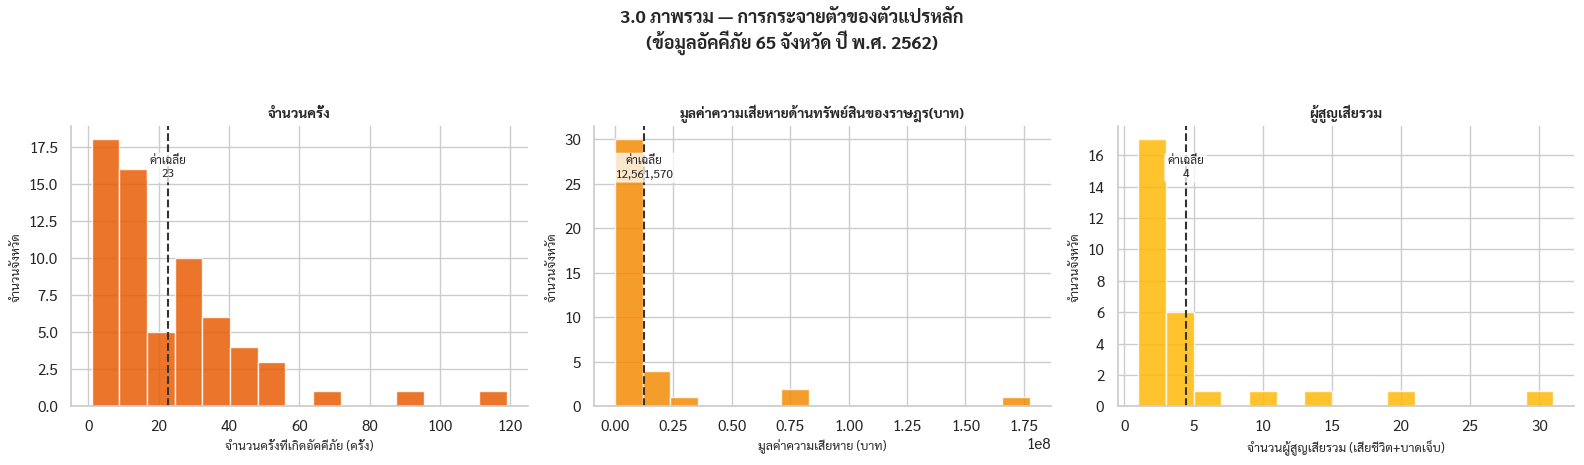

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
fig.suptitle(
    "3.0 ภาพรวม — การกระจายตัวของตัวแปรหลัก\n"
    "(ข้อมูลอัคคีภัย 65 จังหวัด ปี พ.ศ. 2562)",
    fontsize=13, fontweight="bold", y=1.03
)

PLOT_SPECS = [
    ("จำนวนครั้ง",    "จำนวนครั้งที่เกิดอัคคีภัย (ครั้ง)",        "#E85D04"),
    (DMG,             "มูลค่าความเสียหาย (บาท)",                 "#F48C06"),
    ("ผู้สูญเสียรวม", "จำนวนผู้สูญเสียรวม (เสียชีวิต+บาดเจ็บ)", "#FFBA08"),
]
for ax, (col, xlabel, color) in zip(axes, PLOT_SPECS):
    data = df[col][df[col] > 0]
    ax.hist(data, bins=15, color=color, edgecolor="white", alpha=0.85)
    mean_val = data.mean()
    ax.axvline(mean_val, color="#333", ls="--", lw=1.5)
    ax.text(
        mean_val, ax.get_ylim()[1] * 0.82,
        f"ค่าเฉลี่ย\n{mean_val:,.0f}",
        ha="center", fontsize=8.5,
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.75)
    )
    ax.set_xlabel(xlabel, fontsize=9)
    ax.set_ylabel("จำนวนจังหวัด", fontsize=9)
    ax.set_title(col, fontsize=10, fontweight="bold")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("fig_eda_overview.png", dpi=150, bbox_inches="tight")
plt.show()



> Insight: ทั้ง 3 ตัวแปรมีการกระจายแบบ Right-Skewed → ค่าเฉลี่ยถูก outlier ดึงขึ้น → ต้องใช้ Median เป็นเกณฑ์แบ่ง






---



### Per Capita Analysis

In [ ]:
df["เหตุการณ์ต่อประชากร"] = df["จำนวนครั้ง"] / df["ราษฎร(คน)"]
df["ความเสียหายต่อประชากร"] = df[DMG] / df["ราษฎร(คน)"]

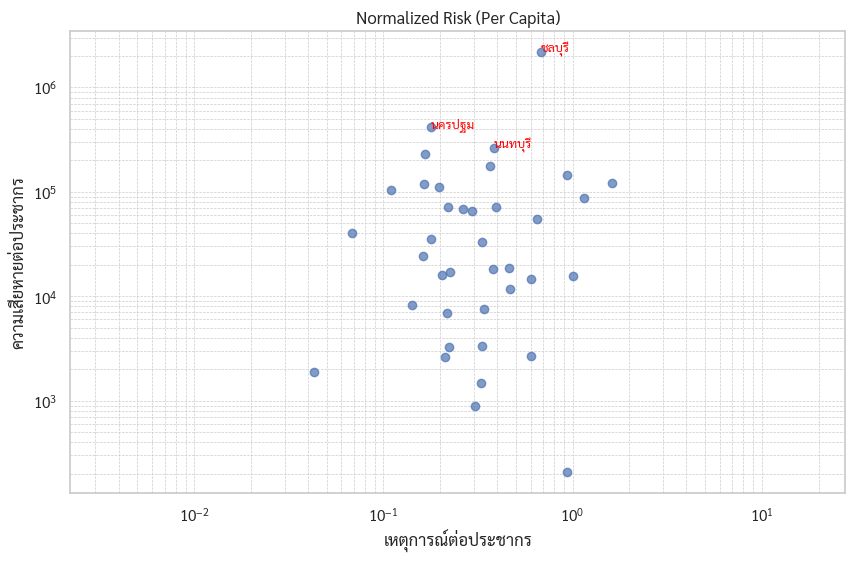

In [ ]:
plt.figure(figsize=(10,6))

# 1. plot จุดก่อน
plt.scatter(
    df["เหตุการณ์ต่อประชากร"],
    df["ความเสียหายต่อประชากร"],
    alpha=0.7
)
# 2. log scale
plt.xscale("log")
plt.yscale("log")

# 3. annotate (ค่อยใส่ทีหลัง)
top = df.nlargest(3, "ความเสียหายต่อประชากร")

for _, row in top.iterrows():
    plt.annotate(
        row["จังหวัด"],
        (row["เหตุการณ์ต่อประชากร"], row["ความเสียหายต่อประชากร"]),
        fontsize=9,
        color="red"
    )

# 4. label
plt.xlabel("เหตุการณ์ต่อประชากร")
plt.ylabel("ความเสียหายต่อประชากร")
plt.title("Normalized Risk (Per Capita)")

plt.grid(True, which="both", linestyle="--", linewidth=0.5)

plt.show()

การวิเคราะห์แบบต่อประชากร (per capita) เปิดเผยความเสี่ยงที่ถูกซ่อน
ซึ่งไม่สามารถเห็นได้จากค่ารวม

พบว่ามีบางจังหวัดที่จำนวนเหตุการณ์ไม่สูง
แต่มีความเสียหายต่อประชากรสูงมาก (outlier)
สะท้อนถึงความเสี่ยงแบบ “เกิดน้อยแต่รุนแรง”

ในขณะที่บางจังหวัดมีเหตุการณ์เกิดบ่อย
แต่ผลกระทบต่อประชากรต่ำกว่า

ดังนั้น การจัดการความเสี่ยงควรแบ่งเป็น 2 กลยุทธ์:
(1) พื้นที่เหตุการณ์สูง → ป้องกันการเกิดซ้ำ  
(2) พื้นที่ impact สูง → เพิ่มความพร้อมตอบสนองฉุกเฉิน



---



### Killer Chart

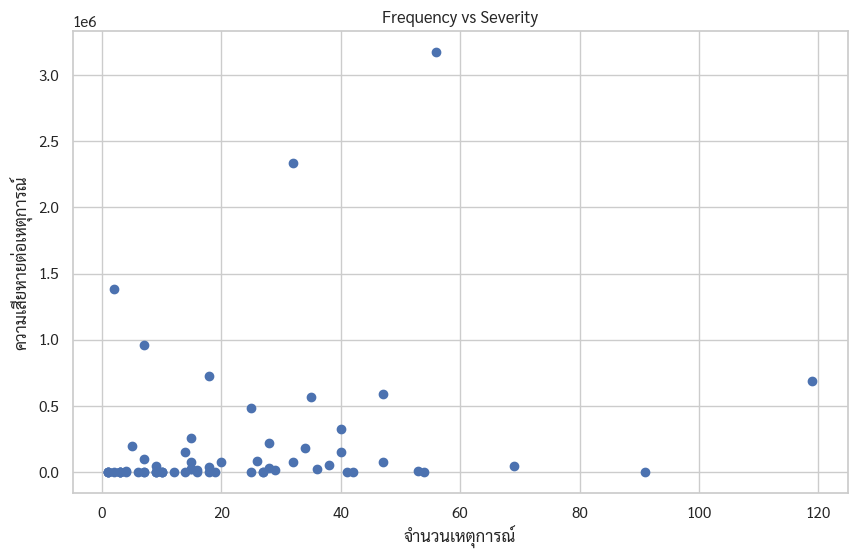

In [ ]:
plt.figure(figsize=(10,6))
plt.scatter(df["จำนวนครั้ง"], df["ความเสียหายต่อครั้ง"])
plt.xlabel("จำนวนเหตุการณ์")
plt.ylabel("ความเสียหายต่อเหตุการณ์")
plt.title("Frequency vs Severity")
plt.show()



> พบ pattern 2 กลุ่มหลัก:
- จังหวัดที่เกิดบ่อยแต่เสียหายน้อย (frequent but low impact)
- จังหวัดที่เกิดน้อยแต่เสียหายหนัก (rare but severe)

ซึ่งต้องใช้ strategy การป้องกันที่แตกต่างกัน





---



### ข้อ 1: คำถามที่ 1 จังหวัดใดมีความเสี่ยงจากอัคคีภัยสูงจริง (True Risk Profile)
คำนวณ Median และกำหนด Quadrant

ใช้ Median (ไม่ใช่ Mean) เพราะข้อมูล skewed มาก
Median = "ค่ากลาง" จริง ๆ ที่ไม่ถูก outlier ดึงให้เบี้ยว


> ค่า Median จริงจากข้อมูล:
* จำนวนครั้ง  = 16 ครั้ง
* มูลค่าเสียหาย = ฿250,000

In [ ]:
MED_EVENT  = df["จำนวนครั้ง"].median()
MED_DAMAGE = df[DMG].median()

# นิยาม 4 Quadrant: สี + label
QC = {
    "CRITICAL":       "#FF4136",
    "DAMAGE HOTSPOT": "#FF851B",
    "FREQUENCY RISK": "#FFDC00",
    "LOW RISK":       "#3D9970",
}
QL_TH = {
    "CRITICAL":
        f"🔴 CRITICAL\nเหตุ ≥{MED_EVENT:.0f} ครั้ง + เสียหาย ≥฿{MED_DAMAGE/1000:.0f}K",
    "DAMAGE HOTSPOT": "🟠 DAMAGE HOTSPOT\nเหตุน้อย แต่เสียหายสูง",
    "FREQUENCY RISK": "🟡 FREQUENCY RISK\nเหตุบ่อย แต่เสียหายน้อย",
    "LOW RISK":       "🟢 LOW RISK\nเหตุน้อย + เสียหายน้อย",
}

def assign_quadrant(row):
    he = row["จำนวนครั้ง"] >= MED_EVENT
    hd = row[DMG]           >= MED_DAMAGE
    if he and hd:     return "CRITICAL"
    if not he and hd: return "DAMAGE HOTSPOT"
    if he and not hd: return "FREQUENCY RISK"
    return "LOW RISK"

df["quadrant"] = df.apply(assign_quadrant, axis=1)
df["q_color"]  = df["quadrant"].map(QC)

print(f"Median จำนวนครั้ง  : {MED_EVENT:.0f} ครั้ง")
print(f"Median มูลค่าเสียหาย: ฿{MED_DAMAGE:,.0f}")
print()
print(df["quadrant"].value_counts().to_string())

Median จำนวนครั้ง  : 16 ครั้ง
Median มูลค่าเสียหาย: ฿250,000

quadrant
CRITICAL          23
LOW RISK          22
DAMAGE HOTSPOT    10
FREQUENCY RISK    10


#### วาด True Risk Profile (Bubble Scatter)

 Bubble Scatter เลือกเพราะแสดง 3 มิติในกราฟเดียวได้
   แกน X → จำนวนเหตุการณ์
   แกน Y → มูลค่าความเสียหาย
   ขนาด Bubble → ความเสียหายเฉลี่ยต่อครั้ง (มิติที่ 3)
 เส้น Median แบ่ง 4 Quadrant → อ่านกลุ่มได้ทันที

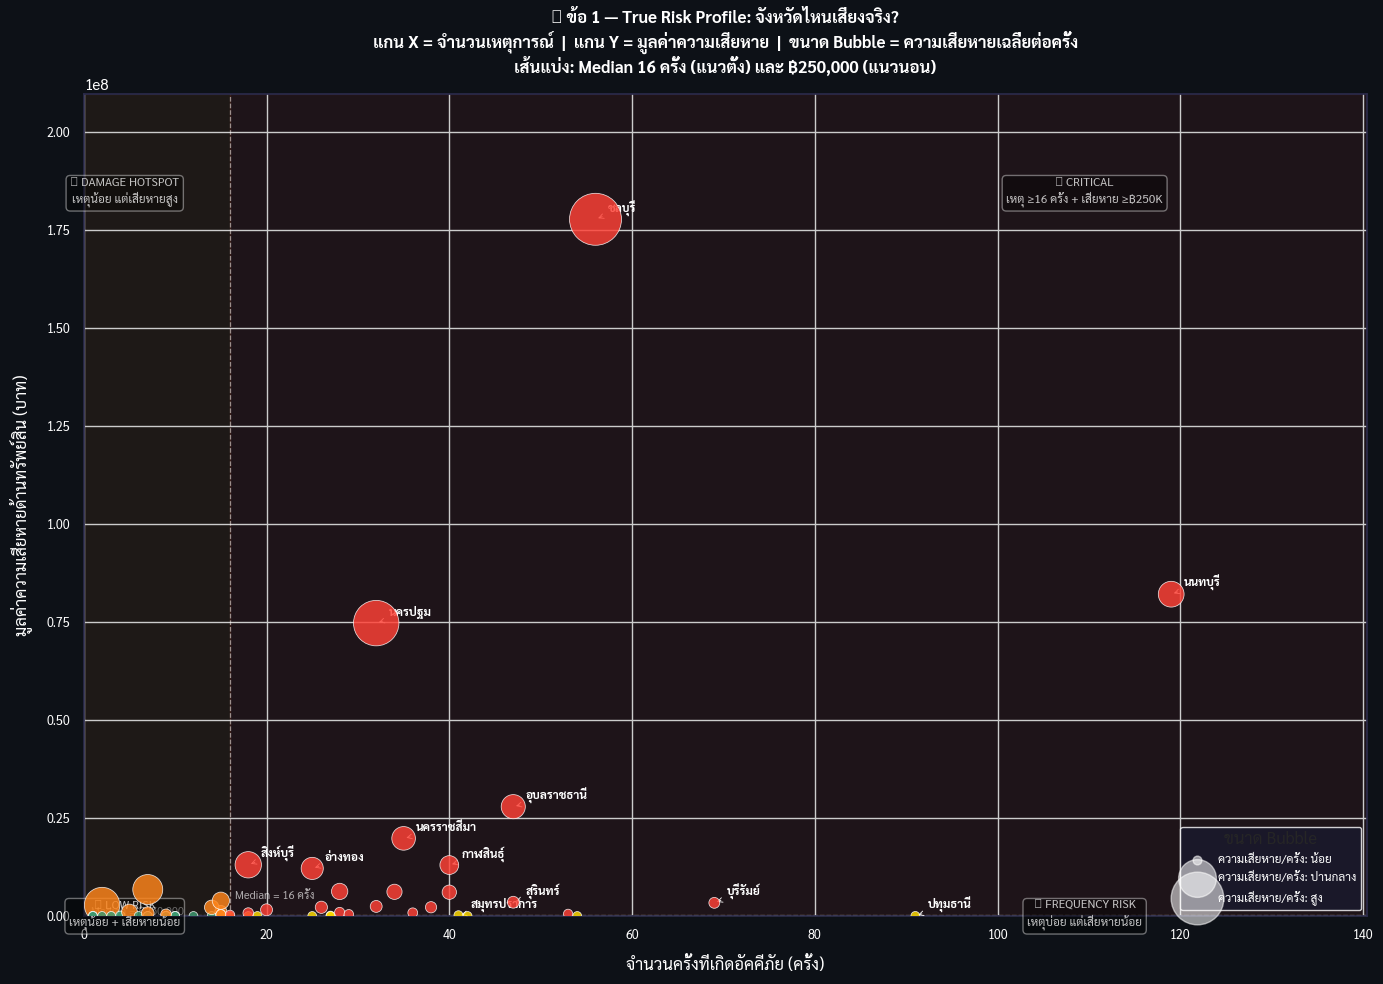

In [ ]:
max_dpe  = df["ความเสียหายต่อครั้ง"].max()
bubble_s = (df["ความเสียหายต่อครั้ง"] / (max_dpe + 1e-9) * 1400 + 40).clip(40, 1400)

fig, ax = plt.subplots(figsize=(14, 10))
fig.patch.set_facecolor("#0D1117")
ax.set_facecolor("#0D1117")

xmax = df["จำนวนครั้ง"].max() * 1.18
ymax = df[DMG].max() * 1.18

# พื้นหลัง Quadrant
for (x0, x1, y0, y1), color in [
    ((MED_EVENT, xmax, MED_DAMAGE, ymax), "#FF4136"),
    ((0, MED_EVENT, MED_DAMAGE, ymax),    "#FF851B"),
    ((MED_EVENT, xmax, 0, MED_DAMAGE),    "#FFDC00"),
    ((0, MED_EVENT, 0, MED_DAMAGE),       "#3D9970"),
]:
    ax.fill_between([x0, x1], [y0, y0], [y1, y1], alpha=0.07, color=color, zorder=0)

# เส้น Median
ax.axvline(MED_EVENT,  color="white", lw=0.9, ls="--", alpha=0.5, zorder=1)
ax.axhline(MED_DAMAGE, color="white", lw=0.9, ls="--", alpha=0.5, zorder=1)
ax.text(MED_EVENT + 0.5, ymax * 0.02, f"Median = {MED_EVENT:.0f} ครั้ง",
        color="white", fontsize=8, alpha=0.65)
ax.text(0.8, MED_DAMAGE * 1.08, f"Median = ฿{MED_DAMAGE:,.0f}",
        color="white", fontsize=8, alpha=0.65)

# วาด Bubble
ax.scatter(df["จำนวนครั้ง"], df[DMG], s=bubble_s, c=df["q_color"],
           alpha=0.83, edgecolors="white", linewidths=0.55, zorder=5)

# label จังหวัดที่น่าสนใจ (เลือกจากข้อมูลจริง)
HIGHLIGHT = [
    "ชลบุรี","นนทบุรี","นครปฐม","อุบลราชธานี","นครราชสีมา",
    "ปทุมธานี","สมุทรปราการ","บุรีรัมย์","สุรินทร์","กาฬสินธุ์",
    "สิงห์บุรี","อ่างทอง"
]
for _, row in df[df["จังหวัด"].isin(HIGHLIGHT)].iterrows():
    ax.annotate(row["จังหวัด"],
                xy=(row["จำนวนครั้ง"], row[DMG]),
                xytext=(9, 5), textcoords="offset points",
                fontsize=8.5, color="white", fontweight="bold",
                arrowprops=dict(arrowstyle="->", color="white", lw=0.6))

# label Quadrant
for qkey, (qx, qy) in [
    ("CRITICAL",       (xmax * 0.78, ymax * 0.88)),
    ("DAMAGE HOTSPOT", (MED_EVENT * 0.28, ymax * 0.88)),
    ("FREQUENCY RISK", (xmax * 0.78, MED_DAMAGE * 0.4)),
    ("LOW RISK",       (MED_EVENT * 0.28, MED_DAMAGE * 0.4)),
]:
    ax.text(qx, qy, QL_TH[qkey], fontsize=8.5, color="white", alpha=0.75,
            ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.35", facecolor="black", alpha=0.4))

# Legend ขนาด bubble
for ratio, label in [(0, "น้อย"), (0.5, "ปานกลาง"), (1.0, "สูง")]:
    ax.scatter([], [], s=(ratio * 1400 + 40), c="white", alpha=0.55,
               label=f"ความเสียหาย/ครั้ง: {label}")
ax.legend(title="ขนาด Bubble", fontsize=8.5, loc="lower right",
          facecolor="#1a1a2e", labelcolor="white", edgecolor="white")

ax.set_xlim(0, xmax); ax.set_ylim(0, ymax)
ax.set_xlabel("จำนวนครั้งที่เกิดอัคคีภัย (ครั้ง)", fontsize=12, color="white", labelpad=10)
ax.set_ylabel("มูลค่าความเสียหายด้านทรัพย์สิน (บาท)", fontsize=12, color="white", labelpad=10)
ax.set_title(
    "🔥 ข้อ 1 — True Risk Profile: จังหวัดไหนเสี่ยงจริง?\n"
    "แกน X = จำนวนเหตุการณ์  |  แกน Y = มูลค่าความเสียหาย  |  ขนาด Bubble = ความเสียหายเฉลี่ยต่อครั้ง\n"
    f"เส้นแบ่ง: Median {MED_EVENT:.0f} ครั้ง (แนวตั้ง) และ ฿{MED_DAMAGE:,.0f} (แนวนอน)",
    fontsize=12, color="white", fontweight="bold", pad=15
)
ax.tick_params(colors="white", labelsize=9)
for spine in ax.spines.values():
    spine.set_edgecolor("#2a2a4a")

plt.tight_layout()
plt.savefig("fig_q1_risk_profile.png", dpi=150, bbox_inches="tight",
            facecolor=fig.get_facecolor())
plt.show()


#### Insight สรุป

In [ ]:
print("=" * 55)
print("📌 สรุป Quadrant จากข้อมูลจริง")
print("=" * 55)
for q in ["CRITICAL", "DAMAGE HOTSPOT", "FREQUENCY RISK", "LOW RISK"]:
    provinces = df[df["quadrant"] == q]["จังหวัด"].tolist()
    print(f"\n{QC[q]} {q} ({len(provinces)} จังหวัด):")
    print("   " + ", ".join(provinces))

📌 สรุป Quadrant จากข้อมูลจริง

#FF4136 CRITICAL (23 จังหวัด):
   กาฬสินธุ์, ขอนแก่น, ชลบุรี, ตาก, นครปฐม, นครราชสีมา, นครศรีธรรมราช, นนทบุรี, บุรีรัมย์, พิษณุโลก, ลำปาง, ลำพูน, สกลนคร, สตูล, สระแก้ว, สิงห์บุรี, สุพรรณบุรี, สุรินทร์, อุดรธานี, อุบลราชธานี, อ่างทอง, เชียงราย, เพชรบุรี

#FF851B DAMAGE HOTSPOT (10 จังหวัด):
   กาญจนบุรี, ฉะเชิงเทรา, บึงกาฬ, พิจิตร, สงขลา, สมุทรสงคราม, หนองบัวลำภู, อุตรดิตถ์, เลย, แพร่

#FFDC00 FREQUENCY RISK (10 จังหวัด):
   ชัยภูมิ, ปทุมธานี, มหาสารคาม, ระยอง, ร้อยเอ็ด, ศรีสะเกษ, สมุทรปราการ, สมุทรสาคร, สระบุรี, สุโขทัย

#3D9970 LOW RISK (22 จังหวัด):
   กระบี่, จันทบุรี, ชัยนาท, ตรัง, ตราด, นครพนม, นครสวรรค์, นราธิวาส, น่าน, ประจวบคีรีขันธ์, ปัตตานี, พระนครศรีอยุธยา, พะเยา, พังงา, พัทลุง, มุกดาหาร, ยะลา, ยโสธร, ราชบุรี, อำนาจเจริญ, เชียงใหม่, เพชรบูรณ์




---



### ข้อ 2: คำถามที่ 2 ความเสียหายจากอัคคีภัยกระจุกตัวอยู่ที่ไหน และรุนแรงเพียงใด (Where & How Severe)
รวมตัวเลขทุก column ของสิ่งปลูกสร้าง group by ภูมิภาค
แล้วเรียงลำดับตามมูลค่าความเสียหาย (มากไปน้อย)


In [ ]:
STRUCT_MAP = {
    "บ้านเรือนทั้งหลัง(หลัง)":    "บ้านเรือน\n(ทั้งหลัง)",
    "บ้านเรือนบางส่วน(หลัง)":     "บ้านเรือน\n(บางส่วน)",
    "อาคารพาณิชย์(หลัง)":         "อาคารพาณิชย์",
    "โรงงาน(แห่ง)":               "โรงงาน",
    "โรงเรือน/โรงเพาะชำ (หลัง)":  "อาคารเกษตร",
    "โกดัง(แห่ง)":                "โกดัง",
    "ร้านค้า (หลัง)":             "ร้านค้า",
}
reg_grp = df.groupby("ภูมิภาค")[list(STRUCT_MAP.keys()) + [DMG]].sum()
reg_grp.rename(columns=STRUCT_MAP, inplace=True)
reg_grp = reg_grp.sort_values(DMG, ascending=False)
SC   = list(STRUCT_MAP.values())
SCOL = ["#E63946","#F4A261","#2A9D8F","#457B9D","#8338EC","#FB5607","#06D6A0"]

print("✅ รวมข้อมูลตามภูมิภาคเรียบร้อย")
print(reg_grp[DMG].apply(lambda x: f"฿{x/1e6:.1f}M").rename("มูลค่าความเสียหาย").to_string())

✅ รวมข้อมูลตามภูมิภาคเรียบร้อย
ภูมิภาค
กลาง        ฿192.2M
ตะวันออก    ฿179.7M
อีสาน        ฿83.5M
เหนือ        ฿13.9M
ใต้           ฿8.1M


#### วาด Stacked Bar + Heatmap
* กราฟซ้าย (Stacked Bar): เห็นว่าแต่ละภูมิภาค "อาคารประเภทไหน" เสียหายมาก
* กราฟขวา (Heatmap): เห็น % การกระจุกตัว → หา Hotspot ได้ทันที

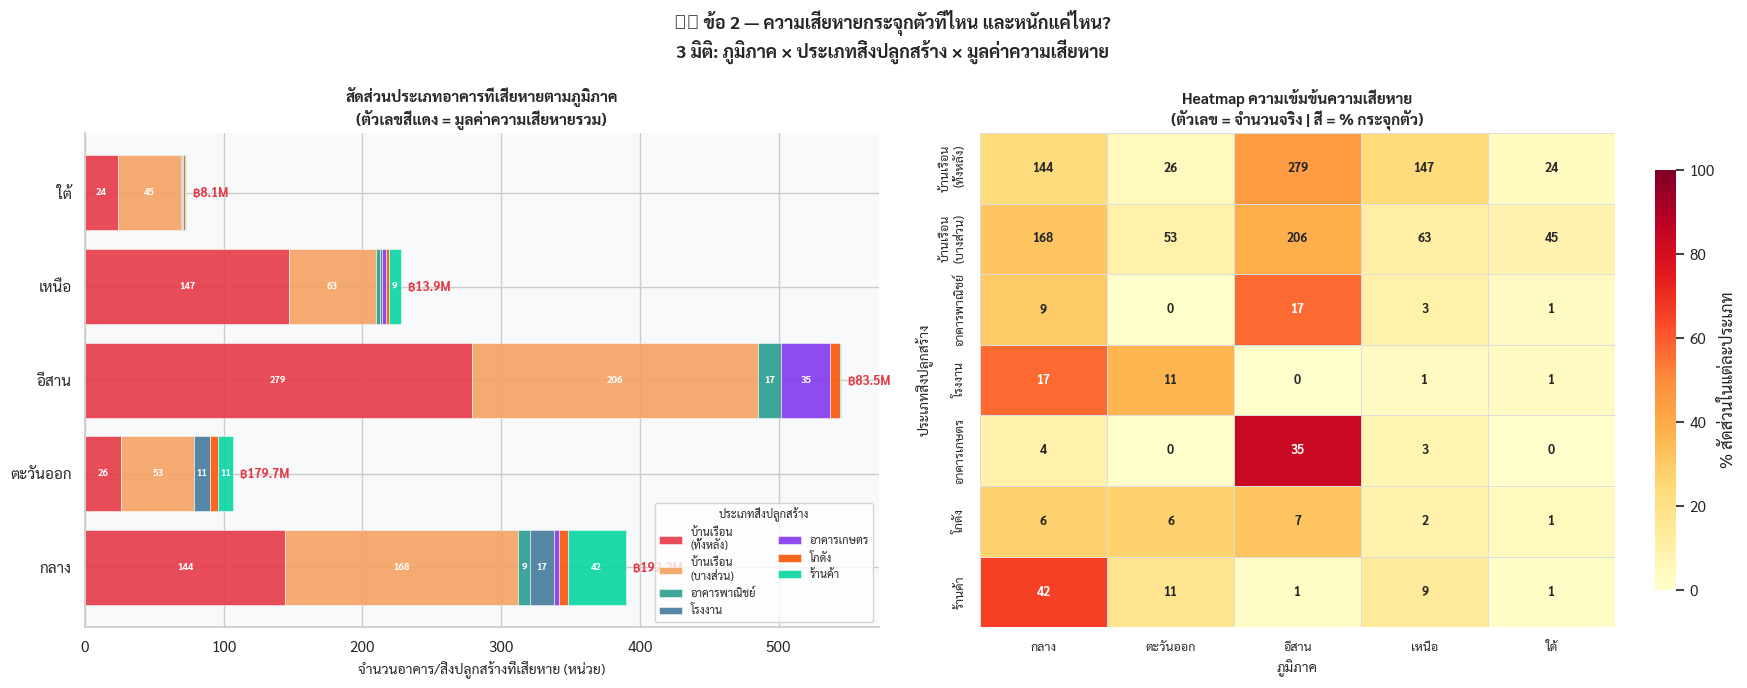

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle(
    "🏚️ ข้อ 2 — ความเสียหายกระจุกตัวที่ไหน และหนักแค่ไหน?\n"
    "3 มิติ: ภูมิภาค × ประเภทสิ่งปลูกสร้าง × มูลค่าความเสียหาย",
    fontsize=13, fontweight="bold"
)

# --- LEFT: Stacked Horizontal Bar ---
ax1 = axes[0]
bottom = np.zeros(len(reg_grp))
for i, col in enumerate(SC):
    vals = reg_grp[col].values.astype(float)
    ax1.barh(reg_grp.index, vals, left=bottom,
             color=SCOL[i], label=col, alpha=0.9, edgecolor="white", lw=0.4)
    for j, v in enumerate(vals):
        if v > 8:
            ax1.text(bottom[j] + v / 2, j, f"{v:.0f}",
                     ha="center", va="center", fontsize=7, color="white", fontweight="bold")
    bottom += vals

for i, (region, row) in enumerate(reg_grp.iterrows()):
    ts = sum(row[c] for c in SC)
    ax1.text(ts + 3, i, f" ฿{row[DMG]/1e6:.1f}M",
             va="center", fontsize=9, color="#E63946", fontweight="bold")

ax1.set_xlabel("จำนวนอาคาร/สิ่งปลูกสร้างที่เสียหาย (หน่วย)", fontsize=10)
ax1.set_title("สัดส่วนประเภทอาคารที่เสียหายตามภูมิภาค\n(ตัวเลขสีแดง = มูลค่าความเสียหายรวม)",
              fontsize=11, fontweight="bold")
ax1.legend(loc="lower right", fontsize=8, ncol=2,
           title="ประเภทสิ่งปลูกสร้าง", title_fontsize=8)
ax1.set_facecolor("#F8F9FA")
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

# --- RIGHT: Heatmap ---
ax2 = axes[1]
hm_data = reg_grp[SC].T
hm_norm = hm_data.div(hm_data.sum(axis=1).replace(0, 1), axis=0) * 100

sns.heatmap(
    hm_norm, ax=ax2, cmap="YlOrRd", vmin=0, vmax=100,
    annot=hm_data.values, fmt=".0f", linewidths=0.6, linecolor="#DDDDDD",
    cbar_kws={"label": "% สัดส่วนในแต่ละประเภท", "shrink": 0.85},
    annot_kws={"size": 9, "weight": "bold"}
)
ax2.set_title("Heatmap ความเข้มข้นความเสียหาย\n(ตัวเลข = จำนวนจริง | สี = % กระจุกตัว)",
              fontsize=11, fontweight="bold")
ax2.set_xlabel("ภูมิภาค", fontsize=10)
ax2.set_ylabel("ประเภทสิ่งปลูกสร้าง", fontsize=10)
ax2.tick_params(labelsize=9)

plt.tight_layout()
plt.savefig("fig_q2_damage_distribution.png", dpi=150, bbox_inches="tight")
plt.show()


#### Top 10 จังหวัดที่เสียหายสูงสุด
* Horizontal Bar ตอบคำถาม "อันดับ" ได้ตรงที่สุด
* label 3 ค่าในแท่งเดียว: มูลค่ารวม + จำนวนครั้ง + ความเสียหายต่อครั้ง

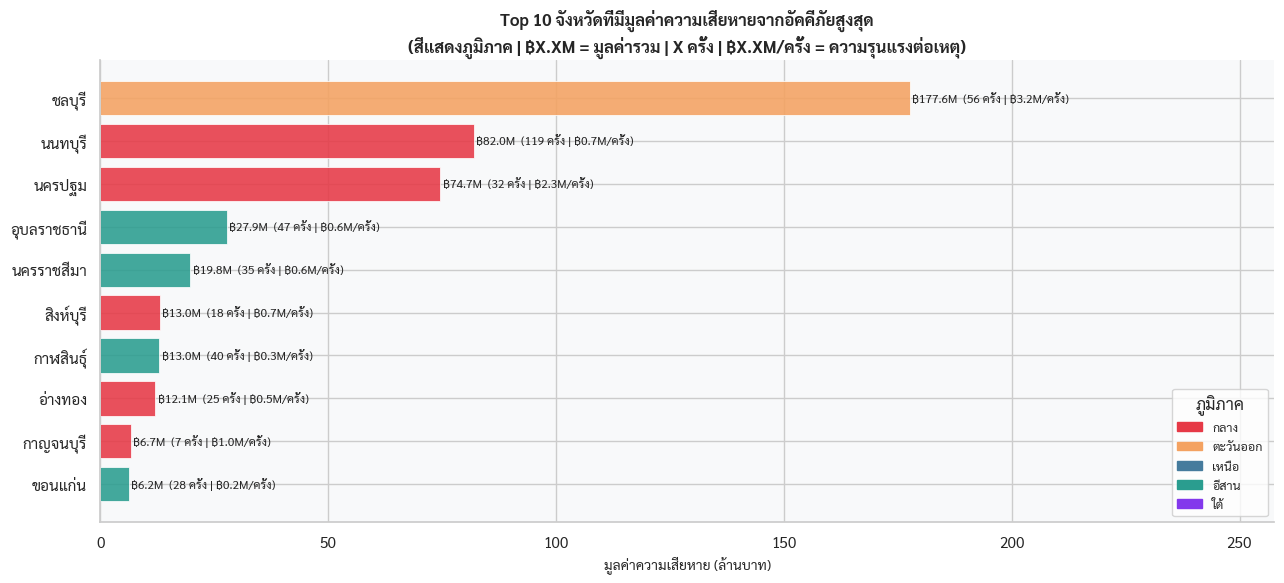

In [ ]:
t10 = df.nlargest(10, DMG)[
    ["จังหวัด", DMG, "จำนวนครั้ง", "ภูมิภาค", "ความเสียหายต่อครั้ง"]
].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(13, 6))
bc = [REGION_PALETTE.get(r, "#999") for r in t10["ภูมิภาค"]]
ax.barh(t10["จังหวัด"][::-1], t10[DMG][::-1] / 1e6,
        color=bc[::-1], alpha=0.88, edgecolor="white", lw=0.6)

for i, (_, row) in enumerate(t10[::-1].iterrows()):
    ax.text(row[DMG] / 1e6 + 0.5, i,
            f"฿{row[DMG]/1e6:.1f}M  ({int(row['จำนวนครั้ง'])} ครั้ง | ฿{row['ความเสียหายต่อครั้ง']/1e6:.1f}M/ครั้ง)",
            va="center", fontsize=8.5)

legend_patches = [mpatches.Patch(color=v, label=k) for k, v in REGION_PALETTE.items()]
ax.legend(handles=legend_patches, title="ภูมิภาค", loc="lower right", fontsize=9)
ax.set_xlabel("มูลค่าความเสียหาย (ล้านบาท)", fontsize=10)
ax.set_title(
    "Top 10 จังหวัดที่มีมูลค่าความเสียหายจากอัคคีภัยสูงสุด\n"
    "(สีแสดงภูมิภาค | ฿X.XM = มูลค่ารวม | X ครั้ง | ฿X.XM/ครั้ง = ความรุนแรงต่อเหตุ)",
    fontsize=12, fontweight="bold"
)
ax.set_facecolor("#F8F9FA")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlim(0, t10[DMG].max() / 1e6 * 1.45)

plt.tight_layout()
plt.savefig("fig_q2_top10_damage.png", dpi=150, bbox_inches="tight")
plt.show()



---



### ข้อ 3: คำถามที่ 3: ปัจจัยใดสัมพันธ์กับความรุนแรงของเหตุอัคคีภัย (What Predicts Severity)

สร้าง DataFrame สำหรับคำนวณ Correlationเลือกตัวแปรที่น่าจะสัมพันธ์กับความรุนแรงของเหตุการณ์


In [ ]:
FEATURE_COLS = [
    "จำนวนครั้ง","ราษฎร(คน)","ราษฎร(ครัวเรือน)",
    "บ้านเรือนทั้งหลัง(หลัง)","บ้านเรือนบางส่วน(หลัง)",
    "โรงงาน(แห่ง)","อาคารพาณิชย์(หลัง)","โกดัง(แห่ง)",
    "โรงเรือน/โรงเพาะชำ (หลัง)","ยานยนต์(คัน)","สิ่งปลูกสร้างรวม"
]
FEATURE_LABELS = {
    "จำนวนครั้ง":                   "จำนวนครั้ง",
    "ราษฎร(คน)":                    "ประชากร",
    "ราษฎร(ครัวเรือน)":             "ครัวเรือน",
    "บ้านเรือนทั้งหลัง(หลัง)":      "บ้านเสียหาย\n(ทั้งหลัง)",
    "บ้านเรือนบางส่วน(หลัง)":       "บ้านเสียหาย\n(บางส่วน)",
    "โรงงาน(แห่ง)":                 "โรงงาน",
    "อาคารพาณิชย์(หลัง)":           "อาคารพาณิชย์",
    "โกดัง(แห่ง)":                  "โกดัง",
    "โรงเรือน/โรงเพาะชำ (หลัง)":   "อาคารเกษตร",
    "ยานยนต์(คัน)":                 "ยานยนต์",
    "สิ่งปลูกสร้างรวม":             "สิ่งปลูกสร้าง\nรวม",
}
SEV_LABEL = "ระดับ\nความรุนแรง"

corr_df = df[FEATURE_COLS + ["ระดับความรุนแรง"]].copy()
corr_df.rename(columns=FEATURE_LABELS, inplace=True)
corr_df.rename(columns={"ระดับความรุนแรง": SEV_LABEL}, inplace=True)
corr_matrix = corr_df.corr()

# แสดง Top correlation กับ Severity ก่อน plot
sev_corr = corr_matrix[SEV_LABEL].drop(SEV_LABEL).sort_values(ascending=False)
print("ลำดับ correlation กับระดับความรุนแรง:")
for k, v in sev_corr.items():
    bar = "█" * int(abs(v) * 20)
    print(f"  {k:<25}: {v:.3f}  {bar}")

ลำดับ correlation กับระดับความรุนแรง:
  สิ่งปลูกสร้าง
รวม        : 0.748  ██████████████
  โรงงาน                   : 0.733  ██████████████
  จำนวนครั้ง               : 0.704  ██████████████
  บ้านเสียหาย
(บางส่วน)    : 0.666  █████████████
  โกดัง                    : 0.620  ████████████
  บ้านเสียหาย
(ทั้งหลัง)   : 0.475  █████████
  อาคารพาณิชย์             : 0.211  ████
  ยานยนต์                  : 0.124  ██
  ประชากร                  : 0.116  ██
  อาคารเกษตร               : 0.100  ██
  ครัวเรือน                : 0.088  █


#### วาด Correlation Heatmap + Ranked Bar
* กราฟซ้าย (Heatmap): เห็นโครงสร้างความสัมพันธ์ระหว่างตัวแปรทั้งหมด
* กราฟขวา (Ranked Bar): แปลให้เป็น "ลำดับ" ที่อ่านแล้วตัดสินใจได้ทันที

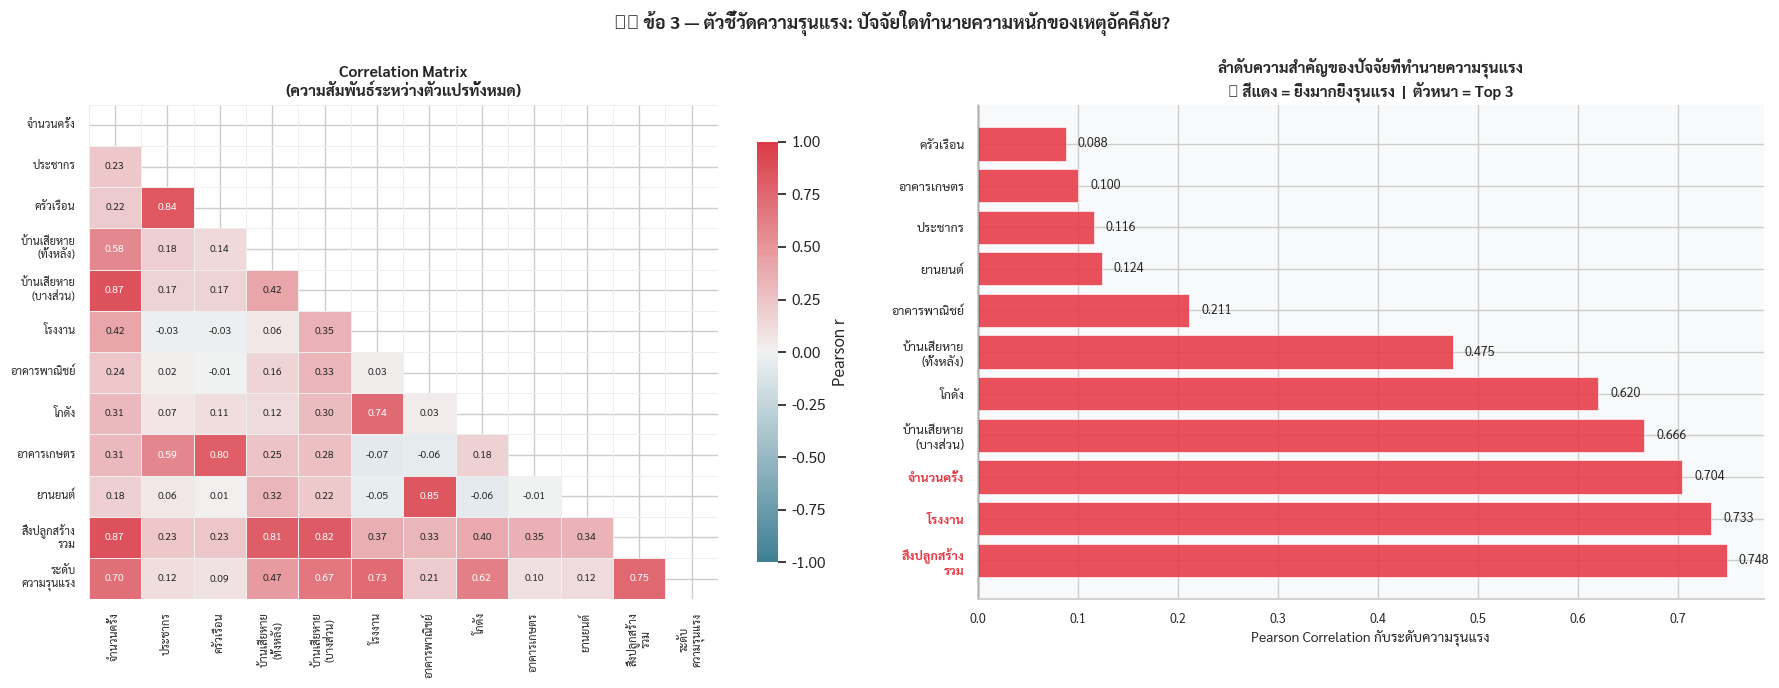

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle(
    "⚠️ ข้อ 3 — ตัวชี้วัดความรุนแรง: ปัจจัยใดทำนายความหนักของเหตุอัคคีภัย?",
    fontsize=13, fontweight="bold"
)

# --- LEFT: Correlation Heatmap (lower triangle เท่านั้น) ---
ax1 = axes[0]
mask = np.zeros_like(corr_matrix, dtype=bool)
mask[np.triu_indices_from(mask)] = True
cmap2 = sns.diverging_palette(220, 10, as_cmap=True)

sns.heatmap(
    corr_matrix, ax=ax1, mask=mask,
    cmap=cmap2, vmin=-1, vmax=1, center=0,
    annot=True, fmt=".2f", annot_kws={"size": 7.5},
    linewidths=0.5, linecolor="#EEEEEE",
    cbar_kws={"shrink": 0.85, "label": "Pearson r"}
)
ax1.set_title("Correlation Matrix\n(ความสัมพันธ์ระหว่างตัวแปรทั้งหมด)",
              fontsize=11, fontweight="bold")
ax1.tick_params(labelsize=8)

# --- RIGHT: Ranked Bar ---
ax2 = axes[1]
bar_colors2 = ["#E63946" if v > 0 else "#457B9D" for v in sev_corr.values]
bars2 = ax2.barh(sev_corr.index, sev_corr.values,
                 color=bar_colors2, alpha=0.88, edgecolor="white", lw=0.5)

for bar, val in zip(bars2, sev_corr.values):
    off = 0.012 if val >= 0 else -0.012
    ax2.text(val + off, bar.get_y() + bar.get_height() / 2,
             f"{val:.3f}", va="center",
             ha="left" if val >= 0 else "right", fontsize=9)

ax2.axvline(0, color="black", lw=0.9)
ax2.set_xlabel("Pearson Correlation กับระดับความรุนแรง", fontsize=10)
ax2.set_title("ลำดับความสำคัญของปัจจัยที่ทำนายความรุนแรง\n"
              "🔴 สีแดง = ยิ่งมากยิ่งรุนแรง  |  ตัวหนา = Top 3",
              fontsize=11, fontweight="bold")
ax2.set_facecolor("#F8F9FA")
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.tick_params(labelsize=9)

# highlight Top 3
for lbl in sev_corr.nlargest(3).index:
    idx = list(sev_corr.index).index(lbl)
    ax2.get_yticklabels()[idx].set_color("#E63946")
    ax2.get_yticklabels()[idx].set_fontweight("bold")

plt.tight_layout()
plt.savefig("fig_q3_severity_factors.png", dpi=150, bbox_inches="tight")
plt.show()


#### Scatter ยืนยัน Top 2 Factors

> Correlation บอกแค่ "ค่า r" แต่ไม่บอก shape ของ relationship
Scatter ช่วยยืนยันว่า relationship นั้น "จริง" ไม่ใช่แค่ outlier เดียว  

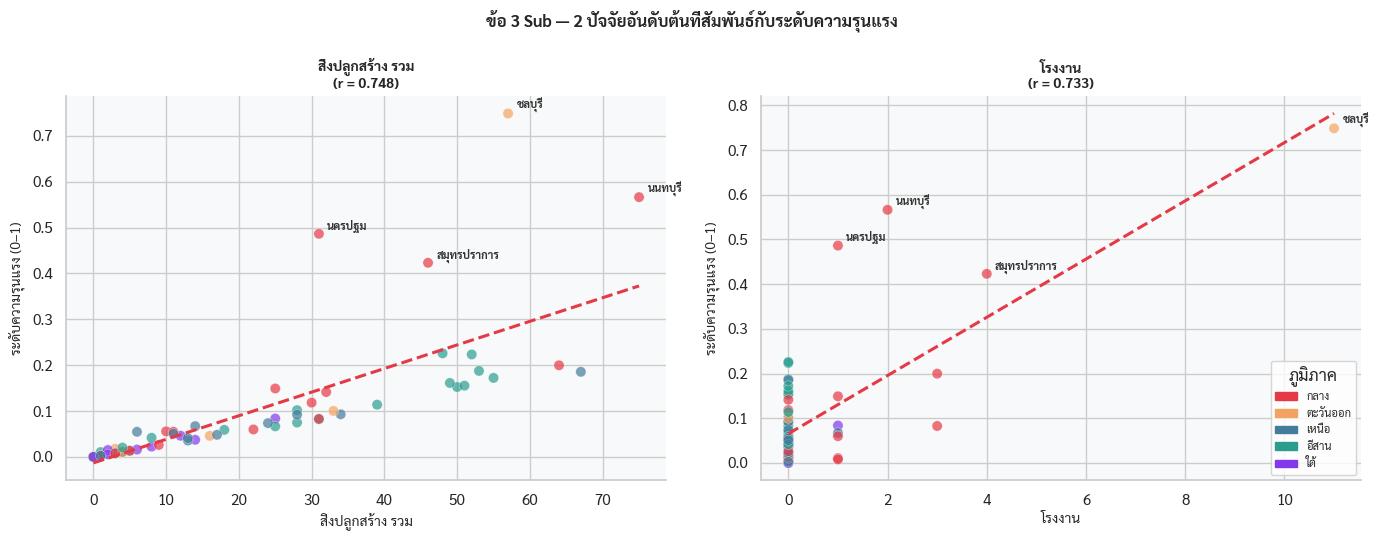

In [ ]:
TOP2_FACTORS = sev_corr.nlargest(2).index.tolist()
REV_LABELS = {v.replace("\n", " "): k for k, v in FEATURE_LABELS.items()}
REV_LABELS.update({v: k for k, v in FEATURE_LABELS.items()})

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
fig.suptitle("ข้อ 3 Sub — 2 ปัจจัยอันดับต้นที่สัมพันธ์กับระดับความรุนแรง",
             fontsize=12, fontweight="bold")

for ax, factor in zip(axes, TOP2_FACTORS):
    raw_col = REV_LABELS.get(factor, None)
    x_data  = df[raw_col] if raw_col and raw_col in df.columns else corr_df[factor]
    y_data  = df["ระดับความรุนแรง"]
    pt_c    = [REGION_PALETTE.get(r, "#aaa") for r in df["ภูมิภาค"]]

    ax.scatter(x_data, y_data, alpha=0.7, s=55, c=pt_c,
               edgecolors="white", linewidths=0.3)

    m, b = np.polyfit(x_data, y_data, 1)
    xl   = np.linspace(x_data.min(), x_data.max(), 100)
    ax.plot(xl, m * xl + b, color="#E63946", lw=2.2, ls="--")

    for _, row in df.nlargest(4, "ระดับความรุนแรง").iterrows():
        val = df.loc[row.name, raw_col] if raw_col and raw_col in df.columns else 0
        ax.annotate(row["จังหวัด"], xy=(val, row["ระดับความรุนแรง"]),
                    fontsize=8, color="#333", fontweight="bold",
                    xytext=(6, 3), textcoords="offset points")

    cv = x_data.corr(y_data)
    ax.set_xlabel(factor.replace("\n", " "), fontsize=10)
    ax.set_ylabel("ระดับความรุนแรง (0–1)", fontsize=10)
    ax.set_title(f"{factor.replace(chr(10), ' ')}\n(r = {cv:.3f})", fontsize=10, fontweight="bold")
    ax.set_facecolor("#F8F9FA")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

legend_patches = [mpatches.Patch(color=v, label=k) for k, v in REGION_PALETTE.items()]
axes[1].legend(handles=legend_patches, title="ภูมิภาค", fontsize=8, loc="lower right")

plt.tight_layout()
plt.savefig("fig_q3_scatter_top2.png", dpi=150, bbox_inches="tight")
plt.show()


**Causation Warning**
⚠️ หมายเหตุ:
Correlation ไม่ได้หมายถึงเหตุและผลโดยตรง
ตัวแปรที่มีความสัมพันธ์สูง เช่น จำนวนสิ่งปลูกสร้าง
อาจเป็นเพียงตัวแทนของความหนาแน่นของพื้นที่
ไม่ใช่สาเหตุโดยตรงของความรุนแรง



---



### ข้อ 4(เสริม): คำนวณ Fire Station Need Score


สมมติฐานของโมเดล:
- ใช้จำนวนอำเภอเป็น proxy ของพื้นที่บริการ
- สมมติว่าสถานีดับเพลิง 1 แห่งรองรับ 1 อำเภอ

ข้อจำกัด:
- ไม่มีข้อมูล response time จริง
- ไม่สะท้อนสภาพจราจรหรือภูมิประเทศ

In [ ]:
df["ภาระต่ออำเภอ"]       = df.apply(
    lambda r: r["จำนวนครั้ง"] / r["อำเภอ"] if r["อำเภอ"] > 0 else 0, axis=1
)
df["ความเสียหายต่ออำเภอ"] = df.apply(
    lambda r: r[DMG] / r["อำเภอ"] if r["อำเภอ"] > 0 else 0, axis=1
)
df["คะแนนความต้องการสถานี"] = (
    df["ภาระต่ออำเภอ"]       / (df["ภาระต่ออำเภอ"].max() + 1e-9)       * 0.5 +
    df["ความเสียหายต่ออำเภอ"] / (df["ความเสียหายต่ออำเภอ"].max() + 1e-9) * 0.5
)

print("✅ คำนวณ Fire Station Need Score เรียบร้อย")
print("\nTop 5 จังหวัดที่ต้องการสถานีดับเพลิงเพิ่มมากที่สุด:")
print(df.nlargest(5, "คะแนนความต้องการสถานี")[
    ["จังหวัด","ภาระต่ออำเภอ","ความเสียหายต่ออำเภอ","คะแนนความต้องการสถานี"]
].to_string(index=False))

✅ คำนวณ Fire Station Need Score เรียบร้อย

Top 5 จังหวัดที่ต้องการสถานีดับเพลิงเพิ่มมากที่สุด:
 จังหวัด  ภาระต่ออำเภอ  ความเสียหายต่ออำเภอ  คะแนนความต้องการสถานี
 นนทบุรี            20           13,672,500                      1
  ชลบุรี             7           22,203,750                      1
  นครปฐม             5           12,444,167                      0
ปทุมธานี            13                2,857                      0
 อ่างทอง             5            2,423,403                      0


#### กำหนด Quadrant ความต้องการสถานี

In [ ]:
NQC = {
    "เร่งด่วนสูงสุด":  "#D62828",
    "เฝ้าระวังรุนแรง": "#F77F00",
    "ขยายสถานี":       "#FCBF49",
    "ระดับปกติ":       "#2A9D8F",
}
NQL = {
    "เร่งด่วนสูงสุด":  "🔴 เร่งด่วนสูงสุด\n(ภาระมาก + เสียหายมาก)",
    "เฝ้าระวังรุนแรง": "🟠 เฝ้าระวังรุนแรง\n(ภาระน้อย + เสียหายมาก)",
    "ขยายสถานี":       "🟡 ขยายสถานี\n(ภาระมาก + เสียหายน้อย)",
    "ระดับปกติ":       "🟢 ระดับปกติ",
}
MB  = df["ภาระต่ออำเภอ"].median()
MDD = df["ความเสียหายต่ออำเภอ"].median()

def assign_nq(row):
    hb = row["ภาระต่ออำเภอ"]       >= MB
    hd = row["ความเสียหายต่ออำเภอ"] >= MDD
    if hb and hd:      return "เร่งด่วนสูงสุด"
    if not hb and hd:  return "เฝ้าระวังรุนแรง"
    if hb and not hd:  return "ขยายสถานี"
    return "ระดับปกติ"

df["nq"] = df.apply(assign_nq, axis=1)

print("✅ จัด Quadrant เรียบร้อย")
print(df["nq"].value_counts().to_string())


✅ จัด Quadrant เรียบร้อย
nq
เร่งด่วนสูงสุด     24
ระดับปกติ          23
เฝ้าระวังรุนแรง     9
ขยายสถานี           9


#### วาดกราฟ Fire Station Need

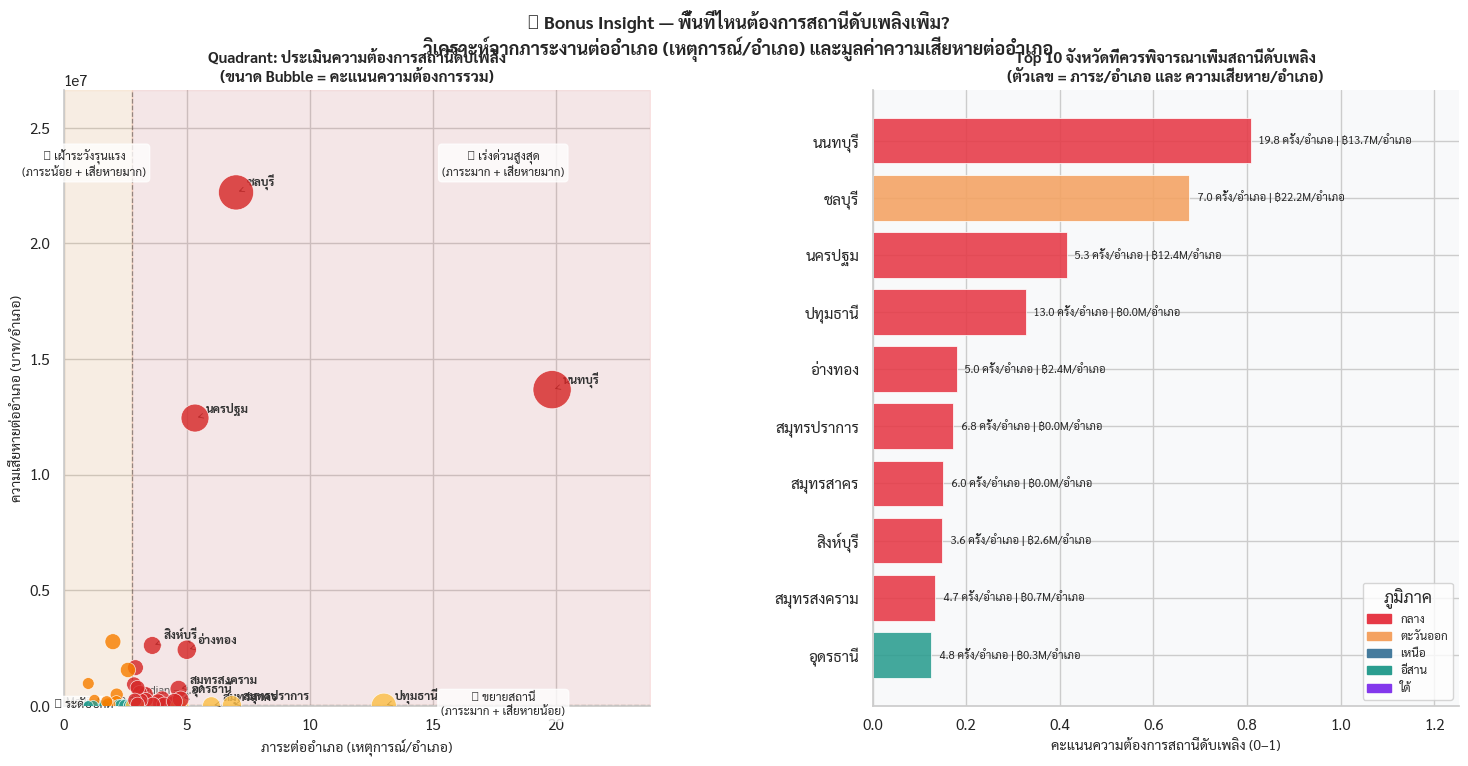

In [ ]:
fig = plt.figure(figsize=(18, 8))
gs  = gridspec.GridSpec(1, 2, figure=fig, wspace=0.38)
axs = fig.add_subplot(gs[0])
axb = fig.add_subplot(gs[1])
fig.suptitle(
    "🚒 Bonus Insight — พื้นที่ไหนต้องการสถานีดับเพลิงเพิ่ม?\n"
    "วิเคราะห์จากภาระงานต่ออำเภอ (เหตุการณ์/อำเภอ) และมูลค่าความเสียหายต่ออำเภอ",
    fontsize=13, fontweight="bold"
)

xm2 = df["ภาระต่ออำเภอ"].max() * 1.2
ym2 = df["ความเสียหายต่ออำเภอ"].max() * 1.2

# พื้นหลัง Quadrant
for (x0, x1, y0, y1), color in [
    ((MB, xm2, MDD, ym2), "#D62828"),((0,  MB,  MDD, ym2), "#F77F00"),
    ((MB, xm2, 0,   MDD), "#FCBF49"),((0,  MB,  0,   MDD), "#2A9D8F"),
]:
    axs.fill_between([x0, x1], [y0, y0], [y1, y1], alpha=0.09, color=color)

axs.axvline(MB,  color="#555", lw=0.9, ls="--", alpha=0.6)
axs.axhline(MDD, color="#555", lw=0.9, ls="--", alpha=0.6)
axs.text(MB + 0.1, ym2 * 0.02, f"Median = {MB:.1f}", fontsize=8, color="#555")
axs.text(0.1, MDD * 1.05, f"Median = ฿{MDD/1e6:.2f}M", fontsize=8, color="#555")

pt_c3 = [NQC[q] for q in df["nq"]]
bs3   = (df["คะแนนความต้องการสถานี"] * 900 + 30).clip(30, 900)
axs.scatter(df["ภาระต่ออำเภอ"], df["ความเสียหายต่ออำเภอ"],
            s=bs3, c=pt_c3, alpha=0.82, edgecolors="white", lw=0.5, zorder=5)

for _, row in df.nlargest(10, "คะแนนความต้องการสถานี").iterrows():
    axs.annotate(row["จังหวัด"],
                 xy=(row["ภาระต่ออำเภอ"], row["ความเสียหายต่ออำเภอ"]),
                 xytext=(8, 4), textcoords="offset points",
                 fontsize=8.5, fontweight="bold", color="#333",
                 arrowprops=dict(arrowstyle="->", color="#333", lw=0.6))

for qkey, (qx, qy) in [
    ("เร่งด่วนสูงสุด",  (xm2 * 0.75, ym2 * 0.88)),
    ("เฝ้าระวังรุนแรง", (MB * 0.3,   ym2 * 0.88)),
    ("ขยายสถานี",       (xm2 * 0.75, MDD * 0.35)),
    ("ระดับปกติ",       (MB * 0.3,   MDD * 0.35)),
]:
    axs.text(qx, qy, NQL[qkey], fontsize=8.5, ha="center", va="center",
             bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.78))

axs.set_xlabel("ภาระต่ออำเภอ (เหตุการณ์/อำเภอ)", fontsize=10)
axs.set_ylabel("ความเสียหายต่ออำเภอ (บาท/อำเภอ)", fontsize=10)
axs.set_title("Quadrant: ประเมินความต้องการสถานีดับเพลิง\n(ขนาด Bubble = คะแนนความต้องการรวม)",
              fontsize=11, fontweight="bold")
axs.set_facecolor("#F8F9FA")
axs.spines["top"].set_visible(False)
axs.spines["right"].set_visible(False)
axs.set_xlim(0, xm2); axs.set_ylim(0, ym2)

# Bar Chart Top 10
t10n = df.nlargest(10, "คะแนนความต้องการสถานี")[
    ["จังหวัด","คะแนนความต้องการสถานี","ภาระต่ออำเภอ","ความเสียหายต่ออำเภอ","ภูมิภาค"]
].reset_index(drop=True)
bc4 = [REGION_PALETTE.get(r, "#999") for r in t10n["ภูมิภาค"]]
axb.barh(t10n["จังหวัด"][::-1], t10n["คะแนนความต้องการสถานี"][::-1],
         color=bc4[::-1], alpha=0.88, edgecolor="white", lw=0.6)

for i, (_, row) in enumerate(t10n[::-1].iterrows()):
    axb.text(row["คะแนนความต้องการสถานี"] + 0.005, i,
             f"  {row['ภาระต่ออำเภอ']:.1f} ครั้ง/อำเภอ | ฿{row['ความเสียหายต่ออำเภอ']/1e6:.1f}M/อำเภอ",
             va="center", fontsize=8)

lp3 = [mpatches.Patch(color=v, label=k) for k, v in REGION_PALETTE.items()]
axb.legend(handles=lp3, title="ภูมิภาค", fontsize=8.5, loc="lower right")
axb.set_xlabel("คะแนนความต้องการสถานีดับเพลิง (0–1)", fontsize=10)
axb.set_title("Top 10 จังหวัดที่ควรพิจารณาเพิ่มสถานีดับเพลิง\n"
              "(ตัวเลข = ภาระ/อำเภอ และ ความเสียหาย/อำเภอ)",
              fontsize=11, fontweight="bold")
axb.set_facecolor("#F8F9FA")
axb.spines["top"].set_visible(False)
axb.spines["right"].set_visible(False)
axb.set_xlim(0, t10n["คะแนนความต้องการสถานี"].max() * 1.55)

plt.tight_layout()
plt.savefig("fig_bonus_firestation_need.png", dpi=150, bbox_inches="tight")
plt.show()



---



## Final Story & Summary
📖 สรุป Data Story — "“ความเสี่ยงอัคคีภัยที่ไม่เท่าเทียม (Unequal Fire Risk in Thailand)”"

จากการวิเคราะห์ข้อมูลอัคคีภัย 65 จังหวัด ปี 2562 เราพบ 4 บทสำคัญ

**🔴 บทที่ 1:** ความเสี่ยงไม่กระจายเท่าเทียม — มี 23 จังหวัดใน CRITICAL
แต่แต่ละจังหวัดเสี่ยง "คนละแบบ" ต้องการมาตรการต่างกัน

**🏚️ บทที่ 2:** ภาคตะวันออกเสียหายมากที่สุด (~38% ของความเสียหายทั้งหมด) ทั้งที่อาคารเสียหายน้อยกว่า
ภาคอีสาน เหตุเพราะโรงงาน EEC มีมูลค่าต่อหน่วยสูงมาก

**⚠️ บทที่ 3:** โรงงาน (r=0.733) คือ "Multiplier" ของความเสียหาย
แม้จะมีน้อยหลัง แต่พอเกิดเหตุที = ความเสียหายพุ่งสูงมาก

**🚒 บทที่ 4:** นนทบุรีรับภาระ 19.8 เหตุ/อำเภอ — สูงสุดในประเทศ
ต้องการสถานีดับเพลิงเพิ่มอย่างเร่งด่วน

1. ชลบุรี (High damage/event)
   → บังคับใช้มาตรฐานความปลอดภัยในโรงงาน + ตรวจสอบประจำปี

2. นนทบุรี (High frequency)
   → เพิ่ม Fire Station + ลด response time

3. ฉะเชิงเทรา (Damage hotspot)
   → ตรวจ audit อาคารพาณิชย์/โกดัง

4. เชียงใหม่ (Frequency risk)
   → เน้น prevention (ชุมชน + ป่า/ที่โล่ง)

5. Early Warning
   → จังหวัดที่ “โรงงาน + สิ่งปลูกสร้างสูง” = เฝ้าระวังพิเศษ

### Policy Recommendation (ข้อเสนอเชิงนโยบาย)

1. จัดลำดับความสำคัญการลงทุน:
   - Tier 1: จังหวัด CRITICAL (ภาคกลาง + เมืองเศรษฐกิจ)
   - Tier 2: Damage Hotspot (เช่น ภาคตะวันออก/เขตอุตสาหกรรม)
   - Tier 3: Frequency Risk (พื้นที่เกิดเหตุบ่อย)

2. มาตรการเฉพาะพื้นที่:
   - เขตอุตสาหกรรม → บังคับใช้ระบบป้องกัน (Sprinkler / Inspection)
   - เมืองหนาแน่น → เพิ่มสถานีดับเพลิง + response unit

3. ระบบ Early Warning:
   ใช้ “จำนวนสิ่งปลูกสร้าง + โรงงาน” เป็นตัว trigger เฝ้าระวัง

In [ ]:
print("=" * 55)
print("📊 สถิติสุดท้าย — ยืนยันตรงกับ Excel ต้นฉบับ")
print("=" * 55)
print(f"  จำนวนจังหวัด              : {len(df):,} จังหวัด")
print(f"  เหตุการณ์รวม              : {df['จำนวนครั้ง'].sum():,.0f} ครั้ง")
print(f"  มูลค่าความเสียหายรวม      : ฿{df[DMG].sum():,.0f}")
print(f"  ผู้เสียชีวิตรวม           : {df['ราษฎรเสียชีวิต(คน)'].sum():.0f} คน")
print(f"  ผู้บาดเจ็บรวม             : {df['ราษฎรบาดเจ็บ(คน)'].sum():.0f} คน")
print(f"  บ้านเรือนเสียหายทั้งหลัง  : {df['บ้านเรือนทั้งหลัง(หลัง)'].sum():.0f} หลัง")
print(f"\n  เหตุบ่อยที่สุด       : {df.loc[df['จำนวนครั้ง'].idxmax(),'จังหวัด']} ({df['จำนวนครั้ง'].max():.0f} ครั้ง)")
print(f"  เสียหายมากที่สุด     : {df.loc[df[DMG].idxmax(),'จังหวัด']} (฿{df[DMG].max():,.0f})")
print(f"  ต้องการสถานีเร่งด่วน : {df.loc[df['คะแนนความต้องการสถานี'].idxmax(),'จังหวัด']}")
print("=" * 55)

print("\n✅ Notebook สมบูรณ์! กราฟที่สร้าง:")
for f in ["fig_eda_overview.png", "fig_q1_risk_profile.png",
          "fig_q2_damage_distribution.png", "fig_q2_top10_damage.png",
          "fig_q3_severity_factors.png", "fig_q3_scatter_top2.png",
          "fig_bonus_firestation_need.png"]:
    print(f"  ✔ {f}")

📊 สถิติสุดท้าย — ยืนยันตรงกับ Excel ต้นฉบับ
  จำนวนจังหวัด              : 65 จังหวัด
  เหตุการณ์รวม              : 1,479 ครั้ง
  มูลค่าความเสียหายรวม      : ฿477,339,662
  ผู้เสียชีวิตรวม           : 20 คน
  ผู้บาดเจ็บรวม             : 104 คน
  บ้านเรือนเสียหายทั้งหลัง  : 620 หลัง

  เหตุบ่อยที่สุด       : นนทบุรี (119 ครั้ง)
  เสียหายมากที่สุด     : ชลบุรี (฿177,630,000)
  ต้องการสถานีเร่งด่วน : นนทบุรี

✅ Notebook สมบูรณ์! กราฟที่สร้าง:
  ✔ fig_eda_overview.png
  ✔ fig_q1_risk_profile.png
  ✔ fig_q2_damage_distribution.png
  ✔ fig_q2_top10_damage.png
  ✔ fig_q3_severity_factors.png
  ✔ fig_q3_scatter_top2.png
  ✔ fig_bonus_firestation_need.png


### Conclusion

การวิเคราะห์นี้แสดงให้เห็นว่า ความเสี่ยงของอัคคีภัยไม่ได้กระจายตัวอย่างสม่ำเสมอ
แต่มีลักษณะ “กระจุกตัว” ทั้งในเชิงพื้นที่และประเภทของความเสียหาย

พื้นที่เศรษฐกิจ เช่น ภาคกลางและภาคตะวันออก มีทั้งความถี่และมูลค่าความเสียหายสูง
สะท้อนถึงความเสี่ยงเชิงระบบจากความหนาแน่นของประชากรและกิจกรรมทางเศรษฐกิจ

ขณะเดียวกัน บางจังหวัดมีเหตุการณ์ไม่บ่อย แต่สร้างความเสียหายต่อครั้งสูง
ซึ่งชี้ให้เห็นว่าการประเมินความเสี่ยงต้องพิจารณาทั้ง “ความถี่” และ “ความรุนแรง” ร่วมกัน

ผลการวิเคราะห์ยังพบว่า “จำนวนสิ่งปลูกสร้าง” และ “โรงงาน”
เป็นตัวแปรที่สัมพันธ์กับความรุนแรงของเหตุการณ์มากที่สุด
ซึ่งสามารถใช้เป็นตัวชี้วัดล่วงหน้า (early indicator) สำหรับการเฝ้าระวัง

ดังนั้น การบริหารจัดการอัคคีภัยควรใช้แนวทางแบบแบ่งกลุ่มพื้นที่ (risk-based approach)
โดยจัดลำดับความสำคัญของการลงทุนและมาตรการป้องกันตามระดับความเสี่ยงของแต่ละจังหวัด

แม้การวิเคราะห์นี้จะมีข้อจำกัดด้านข้อมูล (ปีเดียว และไม่มีข้อมูล response time)
แต่สามารถใช้เป็นฐานข้อมูลสำคัญในการสนับสนุนการตัดสินใจเชิงนโยบายได้อย่างมีประสิทธิภาพ



---

